# Imports

In [1]:
# Run this cell first if packages are missing
# !pip install xgboost shap torch scikit-learn matplotlib seaborn

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix,
    f1_score, roc_auc_score, ConfusionMatrixDisplay
)
from sklearn.utils.class_weight import compute_sample_weight

import xgboost as xgb
import shap

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

from IPython.display import display
from itertools import combinations



# Source Extract

In [2]:
# ── Reproducibility ─────────────────────────────────────────
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

# ── Paths ────────────────────────────────────────────────────
BASE_PATH  = r"C:\MY_Files\DE\dcs_data_pipeline\Medallion\Silver Layer"
RQ1_PATH   = os.path.join(BASE_PATH, "rq1_features.parquet")
RQ2_PATH   = os.path.join(BASE_PATH, "rq2_sequences.npz")
RQ2_META   = os.path.join(BASE_PATH, "rq2_metadata.parquet")
SAVE_PATH  = os.path.join(BASE_PATH, "phase4_results")
os.makedirs(SAVE_PATH, exist_ok=True)

# ── Constants ────────────────────────────────────────────────
FLIGHT_COL   = "mission_id"
MISSION_COL  = "flight_data_mission_type"
BAND_COL     = "band_category"
BASELINE     = "baseline"
LABEL_NAMES  = {
    0: "normal",
    1: "l_engine_fault",
    2: "r_engine_fault",
    3: "dual_engine_fault"
}
RQ2_LABEL_NAMES = {
    0: "l_engine_fault",
    1: "r_engine_fault",
    2: "dual_engine_fault"
}
DOMAIN_MAP = {
    "Thermal"    : ["sensors_temp_l",   "sensors_temp_r",
                    "sensors_fire_l",   "sensors_fire_r"],
    "Mechanical" : ["sensors_rpm_l",    "sensors_rpm_r",
                    "sensors_hyd_fail"],
    "Aerodynamic": ["sensors_aoa",      "sensors_roll",
                    "sensors_pitch",    "sensors_tas",
                    "sensors_alt_baro", "sensors_vsi",
                    "sensors_mach",     "sensors_g_load"],
    "Motion"     : ["sensors_roll_rate","sensors_pitch_rate",
                    "sensors_yaw_rate", "sensors_yaw",
                    "sensors_vel_x",    "sensors_vel_y",
                    "sensors_vel_z",    "sensors_master_warn"],
}

print("✅ Imports complete")
print(f"   PyTorch version : {torch.__version__}")
print(f"   XGBoost version : {xgb.__version__}")
print(f"   SHAP version    : {shap.__version__}")
print(f"   Results will be saved to: {SAVE_PATH}")

✅ Imports complete
   PyTorch version : 2.11.0+cpu
   XGBoost version : 3.2.0
   SHAP version    : 0.51.0
   Results will be saved to: C:\MY_Files\DE\dcs_data_pipeline\Medallion\Silver Layer\phase4_results


# Load Data

In [3]:
# ============================================================
# CELL 1 — LOAD DATA
# ============================================================

# ── RQ1 ─────────────────────────────────────────────────────
rq1_df = pd.read_parquet(RQ1_PATH)

META_COLS    = ["mission_id", "mission_type", "band",
                "label", "w_start", "w_end"]
FEATURE_COLS = [c for c in rq1_df.columns if c not in META_COLS]

print("RQ1 Dataset:")
print(f"  Shape         : {rq1_df.shape}")
print(f"  Feature cols  : {len(FEATURE_COLS)}")
print(f"  Label dist    :")
for lbl, cnt in rq1_df["label"].value_counts().sort_index().items():
    print(f"    {LABEL_NAMES[lbl]:20s}: {cnt:,} ({cnt/len(rq1_df)*100:.1f}%)")

# ── RQ2 ─────────────────────────────────────────────────────
rq2_data     = np.load(RQ2_PATH)
X_rq2        = rq2_data["X"].astype(np.float32)
y_rq2        = rq2_data["y"].astype(np.int64)
RQ2_CHANNELS = list(rq2_data["channels"])
rq2_meta_df  = pd.read_parquet(RQ2_META)

print(f"\nRQ2 Dataset:")
print(f"  X shape       : {X_rq2.shape}")
print(f"  y shape       : {y_rq2.shape}")
print(f"  Channels      : {len(RQ2_CHANNELS)}")
print(f"  Label dist    :")
for lbl, cnt in pd.Series(y_rq2).value_counts().sort_index().items():
    print(f"    {RQ2_LABEL_NAMES[lbl]:20s}: {cnt}")

RQ1 Dataset:
  Shape         : (20131, 795)
  Feature cols  : 789
  Label dist    :
    normal              : 14,319 (71.1%)
    l_engine_fault      : 1,530 (7.6%)
    r_engine_fault      : 1,597 (7.9%)
    dual_engine_fault   : 2,685 (13.3%)

RQ2 Dataset:
  X shape       : (216, 450, 23)
  y shape       : (216,)
  Channels      : 23
  Label dist    :
    l_engine_fault      : 72
    r_engine_fault      : 72
    dual_engine_fault   : 72


# Train Test Split

In [4]:
# ============================================================
# CELL 2 — MASTER TRAIN/TEST SPLIT (FLIGHT LEVEL)
# Stratified by (mission_type, band_category)
# Same split used for BOTH RQ1 and RQ2
# ============================================================

from sklearn.model_selection import train_test_split

# ── Build flight-level metadata ──────────────────────────────
flight_meta = (
    rq1_df[[FLIGHT_COL, "mission_type", "band"]]
    .drop_duplicates(subset=FLIGHT_COL)
    .reset_index(drop=True)
)

# Stratification key: mission_type + band
flight_meta["strat_key"] = (
    flight_meta["mission_type"] + "__" + flight_meta["band"]
)

# Remove strat keys with < 2 samples (can't split)
strat_counts = flight_meta["strat_key"].value_counts()
valid_keys   = strat_counts[strat_counts >= 2].index
flight_meta  = flight_meta[flight_meta["strat_key"].isin(valid_keys)]

train_flights, test_flights = train_test_split(
    flight_meta[FLIGHT_COL].to_numpy(),          # ← .to_numpy() instead of .values
    test_size    = 0.20,
    random_state = SEED,
    stratify     = flight_meta["strat_key"].to_numpy()   # ← same here
)

train_flights = set(train_flights)
test_flights  = set(test_flights)

print("=" * 60)
print("MASTER TRAIN/TEST SPLIT")
print("=" * 60)
print(f"  Total flights  : {len(train_flights) + len(test_flights)}")
print(f"  Train flights  : {len(train_flights)} ({len(train_flights)/(len(train_flights)+len(test_flights))*100:.1f}%)")
print(f"  Test flights   : {len(test_flights)}  ({len(test_flights)/(len(train_flights)+len(test_flights))*100:.1f}%)")

# Verify stratification
print("\nFlight distribution per mission_type × split:")
flight_meta["split"] = flight_meta[FLIGHT_COL].apply(
    lambda x: "train" if x in train_flights else "test"
)
display(
    flight_meta.groupby(["mission_type", "split"])
    .size().unstack(fill_value=0)
)

# Save flight ID lists for reproducibility
pd.Series(list(train_flights)).to_csv(
    os.path.join(SAVE_PATH, "train_flight_ids.csv"), index=False
)
pd.Series(list(test_flights)).to_csv(
    os.path.join(SAVE_PATH, "test_flight_ids.csv"), index=False
)
print("\n✅ Flight ID lists saved")

MASTER TRAIN/TEST SPLIT
  Total flights  : 369
  Train flights  : 295 (79.9%)
  Test flights   : 74  (20.1%)

Flight distribution per mission_type × split:


split,test,train
mission_type,,
baseline,27,126
dual_engine_fault,17,55
l_engine_fault,16,56
r_engine_fault,14,58



✅ Flight ID lists saved


# RQ1

In [12]:
# ============================================================
# CELL 3 — RQ1: APPLY SPLIT + NORMALIZE + CLASS WEIGHTS
# ============================================================

# ── Apply split ──────────────────────────────────────────────
rq1_train = rq1_df[rq1_df[FLIGHT_COL].isin(train_flights)].copy()
rq1_test  = rq1_df[rq1_df[FLIGHT_COL].isin(test_flights)].copy()

X_train_raw = rq1_train[FEATURE_COLS].values.astype(np.float32)
X_test_raw  = rq1_test[FEATURE_COLS].values.astype(np.float32)
y_train_rq1 = rq1_train["label"].values.astype(np.int32)
y_test_rq1  = rq1_test["label"].values.astype(np.int32)

# ── Normalize (fit on train only) ────────────────────────────
scaler_rq1  = StandardScaler()
X_train_rq1 = scaler_rq1.fit_transform(X_train_raw)
X_test_rq1  = scaler_rq1.transform(X_test_raw)

# ── Class weights (handle 71% normal imbalance) ──────────────
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train_rq1
)

print("=" * 60)
print("RQ1 — TRAIN/TEST SPLIT + NORMALIZATION")
print("=" * 60)
print(f"  X_train : {X_train_rq1.shape}")
print(f"  X_test  : {X_test_rq1.shape}")
print(f"  y_train : {np.bincount(y_train_rq1)}")
print(f"  y_test  : {np.bincount(y_test_rq1)}")
print(f"\n  Sample weight range: {sample_weights.min():.4f} – {sample_weights.max():.4f}")
print(f"  Fault windows get {sample_weights[y_train_rq1==1][0]/sample_weights[y_train_rq1==0][0]:.1f}x more weight than normal windows")

RQ1 — TRAIN/TEST SPLIT + NORMALIZATION
  X_train : (15988, 789)
  X_test  : (4143, 789)
  y_train : [11572  1185  1255  1976]
  y_test  : [2747  345  342  709]

  Sample weight range: 0.3454 – 3.3730
  Fault windows get 9.8x more weight than normal windows


In [ ]:
# ============================================================
# CELL 5 — XGBOOST HYPERPARAMETER TUNING (RQ1)
# RandomizedSearchCV with 5-fold CV on training set
# ============================================================

from sklearn.model_selection import RandomizedSearchCV

param_grid = {
    "n_estimators"    : [100, 300, 500],
    "max_depth"       : [3, 5, 7],
    "learning_rate"   : [0.01, 0.05, 0.1],
    "subsample"       : [0.7, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.9, 1.0],
    "min_child_weight": [1, 3, 5],
    "gamma"           : [0, 0.1, 0.3],
}

xgb_base = xgb.XGBClassifier(
    objective        = "multi:softprob",
    num_class        = 4,
    eval_metric      = "mlogloss",
    use_label_encoder= False,
    random_state     = SEED,
    n_jobs           = -1,
    tree_method      = "hist",
)

cv_search = RandomizedSearchCV(
    estimator          = xgb_base,
    param_distributions= param_grid,
    n_iter             = 30,
    scoring            = "f1_macro",
    cv                 = 5,
    random_state       = SEED,
    n_jobs             = -1,
    verbose            = 1,
)

print("Running hyperparameter search (30 iterations × 5-fold CV)...")
cv_search.fit(
    X_train_rq1,
    y_train_rq1,
    sample_weight=sample_weights
)

print(f"\n✅ Best macro F1 (CV): {cv_search.best_score_:.4f}")
print(f"   Best params:")
for k, v in cv_search.best_params_.items():
    print(f"     {k:25s}: {v}")

Running hyperparameter search (30 iterations × 5-fold CV)...
Fitting 5 folds for each of 30 candidates, totalling 150 fits


## RQ1 Training and Evaluation

RQ1 — XGBOOST EVALUATION RESULTS

Macro F1 Score: 0.9914

Classification Report:
                   precision    recall  f1-score   support

           normal       1.00      1.00      1.00      2747
   l_engine_fault       1.00      0.98      0.99       345
   r_engine_fault       0.97      1.00      0.99       342
dual_engine_fault       0.99      0.99      0.99       709

         accuracy                           1.00      4143
        macro avg       0.99      0.99      0.99      4143
     weighted avg       1.00      1.00      1.00      4143

ROC-AUC per class (one-vs-rest):
  normal              : 1.0000
  l_engine_fault      : 1.0000
  r_engine_fault      : 0.9994
  dual_engine_fault   : 0.9988


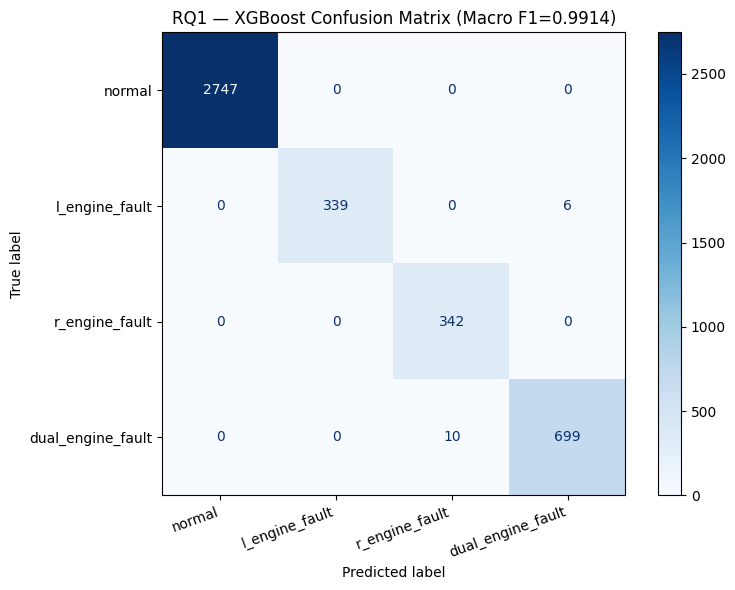


✅ XGBoost model saved


In [ ]:
# ============================================================
# CELL 6 — XGBOOST FINAL TRAINING + EVALUATION (RQ1)
# ============================================================

# ── Train final model with best params ──────────────────────
best_xgb = xgb.XGBClassifier(
    **cv_search.best_params_,
    objective         = "multi:softprob",
    num_class         = 4,
    eval_metric       = "mlogloss",
    use_label_encoder = False,
    random_state      = SEED,
    n_jobs            = -1,
    tree_method       = "hist",
)

best_xgb.fit(
    X_train_rq1,
    y_train_rq1,
    sample_weight = sample_weights,
    eval_set      = [(X_test_rq1, y_test_rq1)],
    verbose       = False,
)

# ── Predictions ──────────────────────────────────────────────
y_pred_rq1      = best_xgb.predict(X_test_rq1)
y_pred_proba    = best_xgb.predict_proba(X_test_rq1)

# ── Metrics ──────────────────────────────────────────────────
macro_f1  = f1_score(y_test_rq1, y_pred_rq1, average="macro")
report    = classification_report(
    y_test_rq1, y_pred_rq1,
    target_names=list(LABEL_NAMES.values())
)

print("=" * 60)
print("RQ1 — XGBOOST EVALUATION RESULTS")
print("=" * 60)
print(f"\nMacro F1 Score: {macro_f1:.4f}")
print(f"\nClassification Report:\n{report}")

# ── ROC-AUC per class ─────────────────────────────────────────
from sklearn.preprocessing import label_binarize
y_test_bin = label_binarize(y_test_rq1, classes=[0,1,2,3])
print("ROC-AUC per class (one-vs-rest):")
for i, name in LABEL_NAMES.items():
    auc = roc_auc_score(y_test_bin[:, i], y_pred_proba[:, i])
    print(f"  {name:20s}: {auc:.4f}")

# ── Confusion matrix ─────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 6))
cm = confusion_matrix(y_test_rq1, y_pred_rq1)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(LABEL_NAMES.values())
)
disp.plot(ax=ax, colorbar=True, cmap="Blues")
ax.set_title(f"RQ1 — XGBoost Confusion Matrix (Macro F1={macro_f1:.4f})")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(SAVE_PATH, "rq1_confusion_matrix.png"), dpi=150)
plt.show()

# ── Save model ───────────────────────────────────────────────
best_xgb.save_model(os.path.join(SAVE_PATH, "xgboost_rq1.json"))
print("\n✅ XGBoost model saved")

In [ ]:
# ── Diagnose Issue 5 ────────────────────────────────────────

# Check if model scores differently on baseline normals
# vs pre-fault normals from fault flights

rq1_test_df = rq1_df[rq1_df[FLIGHT_COL].isin(test_flights)].copy()

# Population A: normal windows from baseline flights
pop_A = rq1_test_df[
    (rq1_test_df["mission_type"] == BASELINE) &
    (rq1_test_df["label"] == 0)
]

# Population B: normal windows from fault flights (pre-fault)
pop_B = rq1_test_df[
    (rq1_test_df["mission_type"] != BASELINE) &
    (rq1_test_df["label"] == 0)
]

X_A = scaler_rq1.transform(pop_A[FEATURE_COLS].values)
X_B = scaler_rq1.transform(pop_B[FEATURE_COLS].values)

pred_A = best_xgb.predict(X_A)
pred_B = best_xgb.predict(X_B)

print("Normal windows from BASELINE flights:")
print(f"  Total      : {len(pred_A)}")
print(f"  Correct (0): {(pred_A == 0).sum()} ({(pred_A == 0).mean()*100:.1f}%)")
print(f"  Misclassified as fault: {(pred_A != 0).sum()}")

print("\nNormal windows from FAULT flights (pre-fault):")
print(f"  Total      : {len(pred_B)}")
print(f"  Correct (0): {(pred_B == 0).sum()} ({(pred_B == 0).mean()*100:.1f}%)")
print(f"  Misclassified as fault: {(pred_B != 0).sum()}")

# If pop_B misclassification is high → model is leaking flight identity
# into pre-fault windows → Issue 5 is real

Normal windows from BASELINE flights:
  Total      : 1598
  Correct (0): 1598 (100.0%)
  Misclassified as fault: 0

Normal windows from FAULT flights (pre-fault):
  Total      : 1149
  Correct (0): 1149 (100.0%)
  Misclassified as fault: 0


In [ ]:
# ── Diagnose Issue 6 ────────────────────────────────────────

# Evaluate on NON-OVERLAPPING windows only (stride = window size)
# If F1 drops significantly → overlap was inflating the score

rq1_test_df = rq1_df[rq1_df[FLIGHT_COL].isin(test_flights)].copy()

# Keep only non-overlapping windows:
# For each flight, keep every other window (stride = window_size)
# w_start increments by WINDOW_S (5s) instead of STRIDE_S (2.5s)
non_overlap = (
    rq1_test_df
    .sort_values([FLIGHT_COL, "w_start"])
    .groupby(FLIGHT_COL)
    .apply(lambda g: g.iloc[::2])   # every other window = non-overlapping
    .reset_index(drop=True)
)

X_no = scaler_rq1.transform(non_overlap[FEATURE_COLS].values)
y_no = non_overlap["label"].values

pred_no = best_xgb.predict(X_no)
f1_no   = f1_score(y_no, pred_no, average="macro")

print(f"F1 with overlapping windows (original) : {macro_f1:.4f}")
print(f"F1 with non-overlapping windows        : {f1_no:.4f}")
print(f"Difference                             : {macro_f1 - f1_no:.4f}")
print()
print(f"Overlapping test windows  : {len(rq1_test_df)}")
print(f"Non-overlapping windows   : {len(non_overlap)}")
print()
print(classification_report(
    y_no, pred_no,
    target_names=list(LABEL_NAMES.values())
))

# If F1 stays high → overlap was not the cause
# If F1 drops significantly → overlap was inflating the score

F1 with overlapping windows (original) : 0.9914
F1 with non-overlapping windows        : 0.9924
Difference                             : -0.0010

Overlapping test windows  : 4143
Non-overlapping windows   : 2094

                   precision    recall  f1-score   support

           normal       1.00      1.00      1.00      1402
   l_engine_fault       1.00      0.99      0.99       173
   r_engine_fault       0.97      1.00      0.99       167
dual_engine_fault       0.99      0.99      0.99       352

         accuracy                           1.00      2094
        macro avg       0.99      0.99      0.99      2094
     weighted avg       1.00      1.00      1.00      2094



In [ ]:
# ── Ablation: train on baseline-only normals ─────────────────
# Remove pre-fault fault-flight windows from training
# Retrain and compare F1

rq1_train_df = rq1_df[rq1_df[FLIGHT_COL].isin(train_flights)].copy()

# Original training set
original_train_mask = rq1_train_df.index

# Ablation: remove pre-fault windows from fault flights
# Keep: all fault windows (label > 0) + baseline normal windows (label = 0, mission = baseline)
ablation_train = rq1_train_df[
    (rq1_train_df["label"] > 0) |
    (rq1_train_df["mission_type"] == BASELINE)
]

X_abl = scaler_rq1.transform(
    ablation_train[FEATURE_COLS].values.astype(np.float32)
)
y_abl = ablation_train["label"].values.astype(np.int32)

sw_abl = compute_sample_weight("balanced", y=y_abl)

# Train ablation model with same best params
abl_model = xgb.XGBClassifier(
    **cv_search.best_params_,
    objective         = "multi:softprob",
    num_class         = 4,
    eval_metric       = "mlogloss",
    use_label_encoder = False,
    random_state      = SEED,
    n_jobs            = -1,
    tree_method       = "hist",
)
abl_model.fit(X_abl, y_abl, sample_weight=sw_abl, verbose=False)

pred_abl = abl_model.predict(X_test_rq1)
f1_abl   = f1_score(y_test_rq1, pred_abl, average="macro")

print("=" * 60)
print("ABLATION — BASELINE-ONLY NORMAL WINDOWS")
print("=" * 60)
print(f"  Original F1 (baseline + pre-fault normals) : {macro_f1:.4f}")
print(f"  Ablation F1 (baseline-only normals)        : {f1_abl:.4f}")
print(f"  Difference                                 : {macro_f1 - f1_abl:.4f}")
print()
print(classification_report(
    y_test_rq1, pred_abl,
    target_names=list(LABEL_NAMES.values())
))

# If F1 stays high → Issue 5 is not inflating results
# If F1 drops → pre-fault fault windows were leaking flight identity

ABLATION — BASELINE-ONLY NORMAL WINDOWS
  Original F1 (baseline + pre-fault normals) : 0.9914
  Ablation F1 (baseline-only normals)        : 0.9925
  Difference                                 : -0.0011

                   precision    recall  f1-score   support

           normal       1.00      1.00      1.00      2747
   l_engine_fault       1.00      0.99      0.99       345
   r_engine_fault       0.97      1.00      0.99       342
dual_engine_fault       0.99      0.99      0.99       709

         accuracy                           1.00      4143
        macro avg       0.99      0.99      0.99      4143
     weighted avg       1.00      1.00      1.00      4143



# RQ2

In [ ]:
# ============================================================
# CELL 4 — RQ2: APPLY SPLIT + NORMALIZE
# ============================================================

# ── Apply split via metadata flight IDs ─────────────────────
rq2_train_mask = rq2_meta_df[FLIGHT_COL].isin(train_flights).values
rq2_test_mask  = rq2_meta_df[FLIGHT_COL].isin(test_flights).values

X_train_seq = X_rq2[rq2_train_mask]   # [n_train × 450 × 23]
X_test_seq  = X_rq2[rq2_test_mask]    # [n_test  × 450 × 23]
y_train_rq2 = y_rq2[rq2_train_mask]
y_test_rq2  = y_rq2[rq2_test_mask]

# ── Z-score normalize per channel (fit on train only) ────────
# Compute mean and std across [n_train × 450] for each channel
train_flat   = X_train_seq.reshape(-1, X_train_seq.shape[-1])  # [(n_train×450) × 23]
ch_mean      = train_flat.mean(axis=0)  # [23]
ch_std       = train_flat.std(axis=0)   # [23]
ch_std       = np.where(ch_std < 1e-8, 1.0, ch_std)  # avoid div by zero

X_train_norm = (X_train_seq - ch_mean) / ch_std
X_test_norm  = (X_test_seq  - ch_mean) / ch_std

# Save normalization params
np.save(os.path.join(SAVE_PATH, "rq2_ch_mean.npy"), ch_mean)
np.save(os.path.join(SAVE_PATH, "rq2_ch_std.npy"),  ch_std)

print("=" * 60)
print("RQ2 — TRAIN/TEST SPLIT + NORMALIZATION")
print("=" * 60)
print(f"  X_train_norm : {X_train_norm.shape}")
print(f"  X_test_norm  : {X_test_norm.shape}")
print(f"  y_train      : {np.bincount(y_train_rq2)}")
print(f"  y_test       : {np.bincount(y_test_rq2)}")
print(f"\n  Channel means (first 5): {ch_mean[:5].round(3)}")
print(f"  Channel stds  (first 5): {ch_std[:5].round(3)}")
print(f"\n✅ RQ2 perfectly balanced — no class weight correction needed")

RQ2 — TRAIN/TEST SPLIT + NORMALIZATION
  X_train_norm : (169, 450, 23)
  X_test_norm  : (47, 450, 23)
  y_train      : [56 58 55]
  y_test       : [16 14 17]

  Channel means (first 5): [8.87033e+02 8.70299e+02 6.43000e-01 6.47000e-01 5.29610e+01]
  Channel stds  (first 5): [207.379 196.761   0.479   0.478  32.742]

✅ RQ2 perfectly balanced — no class weight correction needed


In [ ]:
# ============================================================
# CELL 9 — TRANSFORMER ARCHITECTURE (RQ2)
# ============================================================

class PositionalEncoding(nn.Module):
    def __init__(self, d_model, max_len=500, dropout=0.1):
        super().__init__()
        self.dropout = nn.Dropout(p=dropout)
        pe = torch.zeros(max_len, d_model)
        pos = torch.arange(0, max_len).unsqueeze(1).float()
        div = torch.exp(
            torch.arange(0, d_model, 2).float() *
            (-np.log(10000.0) / d_model)
        )
        pe[:, 0::2] = torch.sin(pos * div)
        pe[:, 1::2] = torch.cos(pos * div)
        self.register_buffer("pe", pe.unsqueeze(0))  # [1 × max_len × d_model]

    def forward(self, x):
        return self.dropout(x + self.pe[:, :x.size(1)])


class TransformerBlock(nn.Module):
    """Single Transformer encoder block with attention weight return."""
    def __init__(self, d_model, nhead, dim_ff, dropout=0.1):
        super().__init__()
        self.attn    = nn.MultiheadAttention(
            d_model, nhead, dropout=dropout, batch_first=True
        )
        self.ff      = nn.Sequential(
            nn.Linear(d_model, dim_ff),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(dim_ff, d_model)
        )
        self.norm1   = nn.LayerNorm(d_model)
        self.norm2   = nn.LayerNorm(d_model)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x, return_attn=False):
        attn_out, attn_w = self.attn(
            x, x, x, need_weights=True, average_attn_weights=True
        )
        x = self.norm1(x + self.dropout(attn_out))
        x = self.norm2(x + self.dropout(self.ff(x)))
        if return_attn:
            return x, attn_w   # attn_w: [batch × seq × seq]
        return x, None


class FaultTransformer(nn.Module):
    def __init__(self, n_channels=23, d_model=64, nhead=4,
                 dim_ff=128, n_layers=2, n_classes=3,
                 max_len=450, dropout=0.1):
        super().__init__()
        self.input_proj = nn.Linear(n_channels, d_model)
        self.pos_enc    = PositionalEncoding(d_model, max_len, dropout)
        self.layers     = nn.ModuleList([
            TransformerBlock(d_model, nhead, dim_ff, dropout)
            for _ in range(n_layers)
        ])
        self.dropout    = nn.Dropout(0.3)
        self.classifier = nn.Linear(d_model, n_classes)

    def forward(self, x, return_attn=False):
        # x: [batch × seq × channels]
        x = self.input_proj(x)          # [batch × seq × d_model]
        x = self.pos_enc(x)

        all_attn = []
        for layer in self.layers:
            x, attn_w = layer(x, return_attn=return_attn)
            if return_attn and attn_w is not None:
                all_attn.append(attn_w)

        x = x.mean(dim=1)               # global average pool [batch × d_model]
        x = self.dropout(x)
        logits = self.classifier(x)     # [batch × n_classes]

        if return_attn:
            return logits, all_attn
        return logits

# ── Verify architecture ──────────────────────────────────────
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model  = FaultTransformer(
    n_channels = len(RQ2_CHANNELS),
    d_model    = 64,
    nhead      = 4,
    dim_ff     = 128,
    n_layers   = 2,
    n_classes  = 3,
    dropout    = 0.1
).to(device)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
print("=" * 60)
print("TRANSFORMER ARCHITECTURE")
print("=" * 60)
print(model)
print(f"\nTotal trainable parameters: {total_params:,}")
print(f"Device: {device}")

# Test forward pass
test_input  = torch.randn(4, 450, len(RQ2_CHANNELS)).to(device)
test_output = model(test_input)
print(f"\n✅ Forward pass: input {test_input.shape} → output {test_output.shape}")

TRANSFORMER ARCHITECTURE
FaultTransformer(
  (input_proj): Linear(in_features=23, out_features=64, bias=True)
  (pos_enc): PositionalEncoding(
    (dropout): Dropout(p=0.1, inplace=False)
  )
  (layers): ModuleList(
    (0-1): 2 x TransformerBlock(
      (attn): MultiheadAttention(
        (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
      )
      (ff): Sequential(
        (0): Linear(in_features=64, out_features=128, bias=True)
        (1): ReLU()
        (2): Dropout(p=0.1, inplace=False)
        (3): Linear(in_features=128, out_features=64, bias=True)
      )
      (norm1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (norm2): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
  )
  (dropout): Dropout(p=0.3, inplace=False)
  (classifier): Linear(in_features=64, out_features=3, bias=True)
)

Total trainable parameters: 68,675
Device: cpu

✅ Forward pass: input torch.Size([4

In [ ]:
# ============================================================
# CELL 10 — TRANSFORMER TRAINING LOOP
# ============================================================

# ── DataLoaders ──────────────────────────────────────────────
BATCH_SIZE = 32

train_ds = TensorDataset(
    torch.FloatTensor(X_train_norm),
    torch.LongTensor(y_train_rq2)
)
test_ds  = TensorDataset(
    torch.FloatTensor(X_test_norm),
    torch.LongTensor(y_test_rq2)
)
train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, shuffle=True,  drop_last=False
)
test_loader  = DataLoader(
    test_ds,  batch_size=BATCH_SIZE, shuffle=False, drop_last=False
)

# ── Training setup ────────────────────────────────────────────
EPOCHS        = 100
PATIENCE      = 15
LR            = 1e-3

criterion     = nn.CrossEntropyLoss()
optimizer     = optim.Adam(model.parameters(), lr=LR, weight_decay=1e-4)
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode="min", factor=0.5, patience=7
)

# ── Training loop ────────────────────────────────────────────
train_losses, val_losses = [], []
train_f1s,    val_f1s    = [], []
best_val_loss = np.inf
patience_ctr  = 0
best_weights  = None

for epoch in range(EPOCHS):
    # ── Train ─────────────────────────────────────────────
    model.train()
    epoch_loss, all_preds, all_labels = 0, [], []

    for xb, yb in train_loader:
        xb, yb = xb.to(device), yb.to(device)
        optimizer.zero_grad()
        logits = model(xb)
        loss   = criterion(logits, yb)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        epoch_loss += loss.item()
        all_preds  += logits.argmax(dim=1).cpu().tolist()
        all_labels += yb.cpu().tolist()

    train_f1   = f1_score(all_labels, all_preds, average="macro")
    avg_t_loss = epoch_loss / len(train_loader)

    # ── Validate ──────────────────────────────────────────
    model.eval()
    val_loss, val_preds, val_labels = 0, [], []

    with torch.no_grad():
        for xb, yb in test_loader:
            xb, yb  = xb.to(device), yb.to(device)
            logits   = model(xb)
            val_loss += criterion(logits, yb).item()
            val_preds  += logits.argmax(dim=1).cpu().tolist()
            val_labels += yb.cpu().tolist()

    avg_v_loss = val_loss / len(test_loader)
    val_f1     = f1_score(val_labels, val_preds, average="macro")

    train_losses.append(avg_t_loss)
    val_losses.append(avg_v_loss)
    train_f1s.append(train_f1)
    val_f1s.append(val_f1)

    scheduler.step(avg_v_loss)

    # ── Early stopping ────────────────────────────────────
    if avg_v_loss < best_val_loss:
        best_val_loss = avg_v_loss
        patience_ctr  = 0
        best_weights  = {
            k: v.clone() for k, v in model.state_dict().items()
        }
    else:
        patience_ctr += 1

    if (epoch + 1) % 10 == 0:
        print(f"  Epoch {epoch+1:3d}/{EPOCHS} | "
              f"Train Loss: {avg_t_loss:.4f} F1: {train_f1:.4f} | "
              f"Val Loss: {avg_v_loss:.4f} F1: {val_f1:.4f} | "
              f"Patience: {patience_ctr}/{PATIENCE}")

    if patience_ctr >= PATIENCE:
        print(f"\n⏹  Early stopping at epoch {epoch+1}")
        break

# Restore best weights
model.load_state_dict(best_weights)
print(f"\n✅ Training complete — best val loss: {best_val_loss:.4f}")

# ── Training curves ───────────────────────────────────────────
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(train_losses, label="Train")
ax1.plot(val_losses,   label="Val")
ax1.set_title("Loss Curve")
ax1.set_xlabel("Epoch"); ax1.set_ylabel("Loss")
ax1.legend()

ax2.plot(train_f1s, label="Train")
ax2.plot(val_f1s,   label="Val")
ax2.set_title("Macro F1 Curve")
ax2.set_xlabel("Epoch"); ax2.set_ylabel("F1 Score")
ax2.legend()

plt.suptitle("RQ2 — Transformer Training Curves")
plt.tight_layout()
plt.savefig(os.path.join(SAVE_PATH, "transformer_training_curves.png"), dpi=150)
plt.show()

KeyboardInterrupt: 

RQ2 — TRANSFORMER EVALUATION RESULTS

Macro F1 Score: 0.9784

Classification Report:
                   precision    recall  f1-score   support

   l_engine_fault       1.00      1.00      1.00        16
   r_engine_fault       0.93      1.00      0.97        14
dual_engine_fault       1.00      0.94      0.97        17

         accuracy                           0.98        47
        macro avg       0.98      0.98      0.98        47
     weighted avg       0.98      0.98      0.98        47

ROC-AUC per class:
  l_engine_fault      : 1.0000
  r_engine_fault      : 0.9697
  dual_engine_fault   : 0.9627


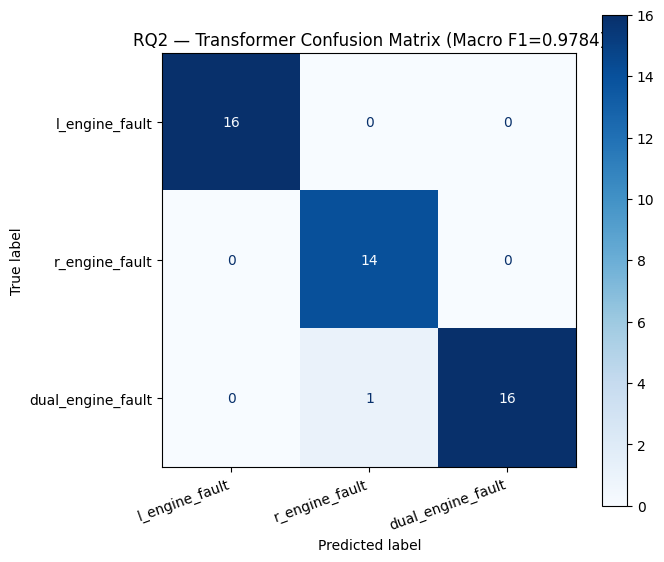


✅ Transformer model saved


In [ ]:
# ============================================================
# CELL 11 — TRANSFORMER EVALUATION (RQ2)
# ============================================================

model.eval()
all_preds, all_labels, all_probs = [], [], []

with torch.no_grad():
    for xb, yb in test_loader:
        xb = xb.to(device)
        logits = model(xb)
        probs  = torch.softmax(logits, dim=1)
        all_preds  += logits.argmax(dim=1).cpu().tolist()
        all_labels += yb.tolist()
        all_probs  += probs.cpu().tolist()

all_preds  = np.array(all_preds)
all_labels = np.array(all_labels)
all_probs  = np.array(all_probs)

macro_f1_rq2 = f1_score(all_labels, all_preds, average="macro")
report_rq2   = classification_report(
    all_labels, all_preds,
    target_names=list(RQ2_LABEL_NAMES.values())
)

print("=" * 60)
print("RQ2 — TRANSFORMER EVALUATION RESULTS")
print("=" * 60)
print(f"\nMacro F1 Score: {macro_f1_rq2:.4f}")
print(f"\nClassification Report:\n{report_rq2}")

# ROC-AUC
y_test_bin_rq2 = label_binarize(all_labels, classes=[0,1,2])
print("ROC-AUC per class:")
for i, name in RQ2_LABEL_NAMES.items():
    auc = roc_auc_score(y_test_bin_rq2[:, i], all_probs[:, i])
    print(f"  {name:20s}: {auc:.4f}")

# Confusion matrix
fig, ax = plt.subplots(figsize=(7, 6))
cm = confusion_matrix(all_labels, all_preds)
ConfusionMatrixDisplay(
    cm, display_labels=list(RQ2_LABEL_NAMES.values())
).plot(ax=ax, cmap="Blues")
ax.set_title(
    f"RQ2 — Transformer Confusion Matrix (Macro F1={macro_f1_rq2:.4f})"
)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(SAVE_PATH, "rq2_confusion_matrix.png"), dpi=150)
plt.show()

torch.save(best_weights, os.path.join(SAVE_PATH, "transformer_rq2.pt"))
print("\n✅ Transformer model saved")

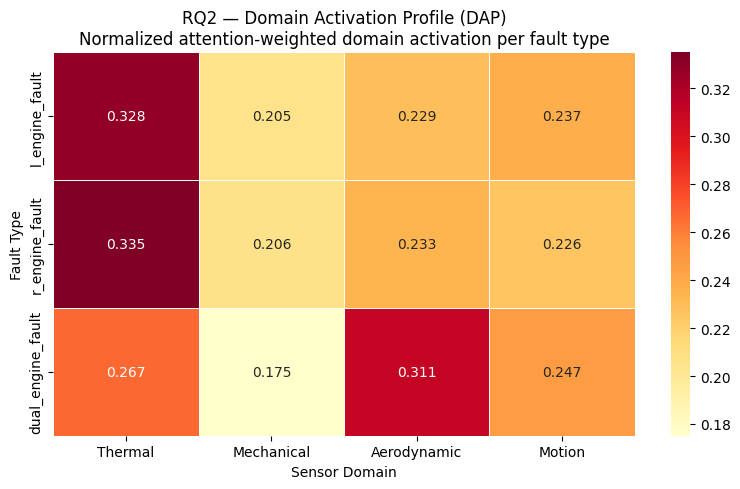

✅ DAP matrix saved


In [ ]:
# ============================================================
# CELL 12 — DAP EXTRACTION (Static Domain Activation Profile)
# ============================================================

model.eval()

# Channel → domain index mapping
ch_domain_idx = []
domain_list = list(DOMAIN_MAP.keys())
for ch in RQ2_CHANNELS:
    assigned = False
    for d_idx, (d_name, d_chs) in enumerate(DOMAIN_MAP.items()):
        if ch in d_chs:
            ch_domain_idx.append(d_idx)
            assigned = True
            break
    if not assigned:
        ch_domain_idx.append(len(domain_list) - 1)  # assign to last domain
ch_domain_idx = np.array(ch_domain_idx)

# Accumulate attention per fault type
dap_accum  = {lbl: np.zeros(len(domain_list))
               for lbl in range(3)}
dap_counts = {lbl: 0 for lbl in range(3)}

X_test_t = torch.FloatTensor(X_test_norm).to(device)

with torch.no_grad():
    for i in range(len(X_test_norm)):
        x   = X_test_t[i:i+1]         # [1 × 450 × 23]
        lbl = all_labels[i]

        _, attn_list = model(x, return_attn=True)
        # attn_list: list of [1 × 450 × 450] per layer

        # Average attention across layers
        avg_attn = torch.stack(
            [a[0] for a in attn_list], dim=0
        ).mean(dim=0).cpu().numpy()    # [450 × 450]

        # Attention received per timestep
        attn_received = avg_attn.sum(axis=0)   # [450]

        # Weight input by attention received
        x_np = x[0].cpu().numpy()              # [450 × 23]
        weighted_input = (attn_received[:, None] * x_np).mean(axis=0)  # [23]

        # Group by domain
        for d_idx in range(len(domain_list)):
            mask = ch_domain_idx == d_idx
            dap_accum[lbl][d_idx] += np.abs(weighted_input[mask]).mean()
        dap_counts[lbl] += 1

# Normalize
dap_matrix = np.zeros((3, len(domain_list)))
for lbl in range(3):
    if dap_counts[lbl] > 0:
        dap_matrix[lbl] = dap_accum[lbl] / dap_counts[lbl]
    row_sum = dap_matrix[lbl].sum()
    if row_sum > 0:
        dap_matrix[lbl] /= row_sum

# Plot DAP heatmap
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(
    dap_matrix,
    annot        = True,
    fmt          = ".3f",
    xticklabels  = domain_list,
    yticklabels  = list(RQ2_LABEL_NAMES.values()),
    cmap         = "YlOrRd",
    linewidths   = 0.5,
    ax           = ax
)
ax.set_title("RQ2 — Domain Activation Profile (DAP)\n"
             "Normalized attention-weighted domain activation per fault type")
ax.set_xlabel("Sensor Domain")
ax.set_ylabel("Fault Type")
plt.tight_layout()
plt.savefig(os.path.join(SAVE_PATH, "dap_heatmap.png"), dpi=150)
plt.show()

np.save(os.path.join(SAVE_PATH, "dap_matrix.npy"), dap_matrix)
print("✅ DAP matrix saved")

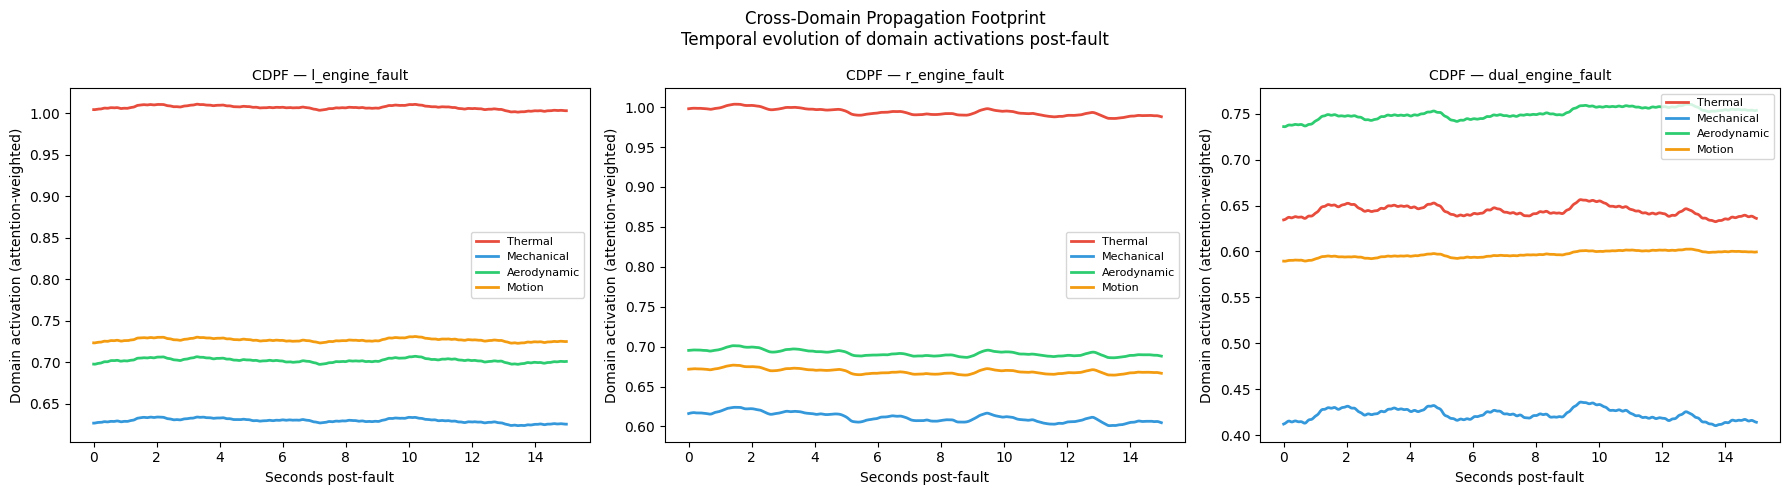

In [ ]:
# ============================================================
# CELL 13 — CROSS-DOMAIN PROPAGATION FOOTPRINT (CDPF)
# ============================================================

N_TIMESTEPS  = 450
SMOOTH_WIN   = 15   # rolling average window for smoothing

cdpf_accum  = {lbl: np.zeros((N_TIMESTEPS, len(domain_list)))
                for lbl in range(3)}
cdpf_counts = {lbl: 0 for lbl in range(3)}

with torch.no_grad():
    for i in range(len(X_test_norm)):
        x   = X_test_t[i:i+1]
        lbl = all_labels[i]

        _, attn_list = model(x, return_attn=True)
        avg_attn     = torch.stack(
            [a[0] for a in attn_list], dim=0
        ).mean(dim=0).cpu().numpy()    # [450 × 450]

        x_np = x[0].cpu().numpy()     # [450 × 23]

        # For each query timestep t: weighted input = sum_k A[t,k] * X[k]
        weighted_seq = avg_attn @ x_np  # [450 × 23]

        # Group by domain per timestep
        for d_idx in range(len(domain_list)):
            mask = ch_domain_idx == d_idx
            cdpf_accum[lbl][:, d_idx] += (
                np.abs(weighted_seq[:, mask]).mean(axis=1)
            )
        cdpf_counts[lbl] += 1

# Average over flights
cdpf_tensor = np.zeros((3, N_TIMESTEPS, len(domain_list)))
for lbl in range(3):
    if cdpf_counts[lbl] > 0:
        cdpf_tensor[lbl] = cdpf_accum[lbl] / cdpf_counts[lbl]

np.save(os.path.join(SAVE_PATH, "cdpf_tensor.npy"), cdpf_tensor)

# ── Propagation timeline plots ────────────────────────────────
time_axis = np.linspace(0, 15, N_TIMESTEPS)
colors    = ["#E74C3C", "#3498DB", "#2ECC71", "#F39C12"]

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, (lbl, lbl_name) in zip(
    axes, RQ2_LABEL_NAMES.items()
):
    for d_idx, (d_name, color) in enumerate(
        zip(domain_list, colors)
    ):
        raw     = cdpf_tensor[lbl, :, d_idx]
        # Smooth
        smooth  = pd.Series(raw).rolling(
            SMOOTH_WIN, center=True, min_periods=1
        ).mean().values
        ax.plot(time_axis, smooth,
                label=d_name, color=color, linewidth=2)

    ax.set_title(f"CDPF — {lbl_name}", fontsize=10)
    ax.set_xlabel("Seconds post-fault")
    ax.set_ylabel("Domain activation (attention-weighted)")
    ax.legend(fontsize=8)

plt.suptitle(
    "Cross-Domain Propagation Footprint\n"
    "Temporal evolution of domain activations post-fault",
    fontsize=12
)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_PATH, "cdpf_timeline.png"), dpi=150)
plt.show()

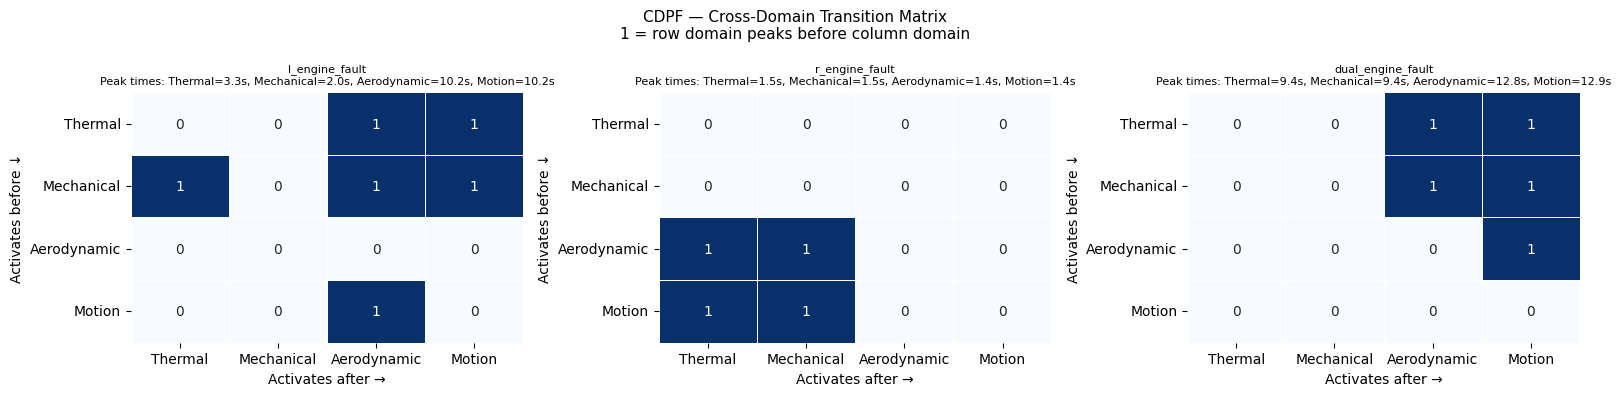

In [ ]:
# ── Cross-domain transition matrix ───────────────────────────

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for ax, (lbl, lbl_name) in zip(axes, RQ2_LABEL_NAMES.items()):
    # Find peak time per domain
    peak_times = {}
    for d_idx, d_name in enumerate(domain_list):
        raw    = cdpf_tensor[lbl, :, d_idx]
        smooth = pd.Series(raw).rolling(
            SMOOTH_WIN, center=True, min_periods=1
        ).mean().values
        peak_times[d_name] = time_axis[np.argmax(smooth)]

    # Build transition matrix: entry [i,j] = 1 if domain i peaks before j
    trans_matrix = np.zeros((len(domain_list), len(domain_list)))
    for i, d_i in enumerate(domain_list):
        for j, d_j in enumerate(domain_list):
            if i != j:
                trans_matrix[i, j] = (
                    1.0 if peak_times[d_i] < peak_times[d_j] else 0.0
                )

    sns.heatmap(
        trans_matrix,
        annot       = True,
        fmt         = ".0f",
        xticklabels = domain_list,
        yticklabels = domain_list,
        cmap        = "Blues",
        ax          = ax,
        cbar        = False,
        linewidths  = 0.5
    )
    ax.set_title(f"{lbl_name}\nPeak times: "
                 + ", ".join([f"{d}={t:.1f}s"
                 for d, t in peak_times.items()]),
                 fontsize=8)
    ax.set_xlabel("Activates after →")
    ax.set_ylabel("Activates before ↓")

plt.suptitle(
    "CDPF — Cross-Domain Transition Matrix\n"
    "1 = row domain peaks before column domain",
    fontsize=11
)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_PATH, "cdpf_transition_matrix.png"), dpi=150)
plt.show()

In [ ]:
# ── Footprint distance between fault types ───────────────────

from numpy.linalg import norm

print("=" * 60)
print("CDPF — PROPAGATION FOOTPRINT DISTANCE")
print("=" * 60)
print("Cosine similarity between propagation sequences:")
print("(Lower = more distinct fingerprints)\n")

fault_pairs = list(combinations(range(3), 2))
for a, b in fault_pairs:
    vec_a = cdpf_tensor[a].flatten()
    vec_b = cdpf_tensor[b].flatten()
    cos_sim = np.dot(vec_a, vec_b) / (norm(vec_a) * norm(vec_b))
    print(f"  {RQ2_LABEL_NAMES[a]:20s} vs "
          f"{RQ2_LABEL_NAMES[b]:20s}: {cos_sim:.4f}")

CDPF — PROPAGATION FOOTPRINT DISTANCE
Cosine similarity between propagation sequences:
(Lower = more distinct fingerprints)

  l_engine_fault       vs r_engine_fault      : 0.9996
  l_engine_fault       vs dual_engine_fault   : 0.9778
  r_engine_fault       vs dual_engine_fault   : 0.9766


In [ ]:
print(rq2_meta_df.columns.tolist())
print(rq2_meta_df.head(3))

['mission_id', 'mission_type', 'band', 'label']
                             mission_id    mission_type  \
0  000febff-1ae2-4a89-9560-f67f4aad4e0a  r_engine_fault   
1  01fd72a4-d178-452a-b76e-f74356d0ddc5  l_engine_fault   
2  0248cb19-fa63-4f57-89ac-f00135bee4ca  r_engine_fault   

                     band  label  
0  r_engine_1000ft_450kts      1  
1  l_engine_1000ft_450kts      0  
2  r_engine_1000ft_400kts      1  


In [ ]:
# ============================================================
# CELL 14 — LEAVE-2-OUT CV (RQ-GEN1)
# ============================================================

print("=" * 60)
print("RQ-GEN1 — LEAVE-2-OUT CROSS VALIDATION")
print("=" * 60)

# Extract altitude-speed condition from band_category
# e.g. "l_engine_1000ft_350kts" → "1000ft_350kts"
def extract_condition(band_str):
    parts = band_str.split("_")
    # Find first part that contains "ft"
    for i, p in enumerate(parts):
        if "ft" in p:
            return "_".join(parts[i:])
    return band_str

rq2_meta_df["condition"] = rq2_meta_df["band"].apply(extract_condition)
conditions = sorted(rq2_meta_df["condition"].unique())
print(f"  Operating conditions: {conditions}")

l2o_results = []
condition_pairs = list(combinations(conditions, 2))
print(f"  Total L2O folds: {len(condition_pairs)}")

for fold_idx, (c1, c2) in enumerate(condition_pairs):
    held_out = {c1, c2}

    # Split by condition
    test_mask_l2o  = rq2_meta_df["condition"].isin(held_out).values
    train_mask_l2o = ~test_mask_l2o

    if test_mask_l2o.sum() == 0 or train_mask_l2o.sum() == 0:
        continue

    X_tr = torch.FloatTensor(X_rq2[train_mask_l2o]).to(device)
    y_tr = torch.LongTensor(y_rq2[train_mask_l2o]).to(device)
    X_te = torch.FloatTensor(X_rq2[test_mask_l2o]).to(device)
    y_te = y_rq2[test_mask_l2o]

    # Normalize on fold train set
    tr_flat   = X_tr.cpu().numpy().reshape(-1, len(RQ2_CHANNELS))
    fold_mean = tr_flat.mean(axis=0)
    fold_std  = tr_flat.std(axis=0)
    fold_std  = np.where(fold_std < 1e-8, 1.0, fold_std)

    X_tr_n = ((X_tr.cpu().numpy() - fold_mean) / fold_std)
    X_te_n = ((X_te.cpu().numpy() - fold_mean) / fold_std)

    # Train a fresh model per fold
    fold_model = FaultTransformer(
        n_channels=len(RQ2_CHANNELS), d_model=64,
        nhead=4, dim_ff=128, n_layers=2, n_classes=3
    ).to(device)

    fold_opt  = optim.Adam(fold_model.parameters(), lr=1e-3)
    fold_crit = nn.CrossEntropyLoss()

    fold_ds = TensorDataset(
        torch.FloatTensor(X_tr_n),
        torch.LongTensor(y_rq2[train_mask_l2o])
    )
    fold_loader = DataLoader(fold_ds, batch_size=32, shuffle=True)

    fold_model.train()
    for ep in range(50):   # shorter training per fold
        for xb, yb in fold_loader:
            xb, yb = xb.to(device), yb.to(device)
            fold_opt.zero_grad()
            loss = fold_crit(fold_model(xb), yb)
            loss.backward()
            fold_opt.step()

    # Evaluate
    fold_model.eval()
    with torch.no_grad():
        logits   = fold_model(
            torch.FloatTensor(X_te_n).to(device)
        )
        fold_pred = logits.argmax(dim=1).cpu().numpy()

    fold_f1 = f1_score(y_te, fold_pred, average="macro",
                       zero_division=0)
    l2o_results.append({
        "held_out_1" : c1,
        "held_out_2" : c2,
        "macro_f1"   : fold_f1,
        "n_test"     : int(test_mask_l2o.sum())
    })

    if (fold_idx + 1) % 6 == 0:
        print(f"  Fold {fold_idx+1:2d}/{len(condition_pairs)} | "
              f"Held out: {c1}, {c2} | F1: {fold_f1:.4f}")

l2o_df = pd.DataFrame(l2o_results)
print(f"\nLeave-2-Out Results:")
print(f"  Mean Macro F1 : {l2o_df['macro_f1'].mean():.4f}")
print(f"  Std  Macro F1 : {l2o_df['macro_f1'].std():.4f}")
print(f"  Min  Macro F1 : {l2o_df['macro_f1'].min():.4f}")
print(f"  Max  Macro F1 : {l2o_df['macro_f1'].max():.4f}")

# Plot L2O distribution
fig, ax = plt.subplots(figsize=(8, 4))
l2o_df["macro_f1"].hist(bins=15, ax=ax, color="#4A90D9", edgecolor="white")
ax.axvline(l2o_df["macro_f1"].mean(), color="red",
           linestyle="--", label=f"Mean={l2o_df['macro_f1'].mean():.3f}")
ax.set_title("RQ-GEN1 — Leave-2-Out F1 Distribution")
ax.set_xlabel("Macro F1")
ax.set_ylabel("# Folds")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(SAVE_PATH, "l2o_distribution.png"), dpi=150)
plt.show()

l2o_df.to_parquet(os.path.join(SAVE_PATH, "l2o_results.parquet"), index=False)

RQ-GEN1 — LEAVE-2-OUT CROSS VALIDATION
  Operating conditions: ['1000ft_350kts', '1000ft_400kts', '1000ft_450kts', '20000ft_350kts', '20000ft_400kts', '20000ft_450kts', '8000ft_350kts', '8000ft_400kts', '8000ft_450kts']
  Total L2O folds: 36


KeyboardInterrupt: 

In [ ]:
# ============================================================
# CELL 15 — FINAL RESULTS SUMMARY
# ============================================================

print()
print("=" * 60)
print("PHASE 4 — COMPLETE RESULTS SUMMARY")
print("=" * 60)

print(f"""
RQ1 — FAULT DETECTION (XGBoost + SHAP)
  Macro F1              : {macro_f1:.4f}
  Top discriminating    : cross__rpm_asymmetry_mean
                          cross__temp_asymmetry_mean
                          cross__fire_l_active / fire_r_active
  Domain contribution   : see shap_domain_contribution.png

RQ2 — FAULT IDENTITY (Transformer)
  Macro F1              : {macro_f1_rq2:.4f}
  DAP                   : see dap_heatmap.png
  CDPF propagation      : see cdpf_timeline.png
  CDPF transition matrix: see cdpf_transition_matrix.png

RQ-GEN1 — GENERALIZATION (Leave-2-Out CV)
  Mean Macro F1         : {l2o_df['macro_f1'].mean():.4f} ± {l2o_df['macro_f1'].std():.4f}

RQ-SEV3 — ASYMMETRY HEALTH INDEX
  see ahi_trajectories.png

RQ-XAI1 — SHAP ONSET SHIFT
  see shap_onset_shift.png

Files saved to: {SAVE_PATH}
""")


PHASE 4 — COMPLETE RESULTS SUMMARY


NameError: name 'l2o_df' is not defined

In [ ]:
# ============================================================
# FIX 1 — SIDED DOMAIN ACTIVATION PROFILE
# 6 side-aware domain groups instead of 4
# ============================================================

SIDED_DOMAIN_MAP = {
    "Thermal_L"   : ["sensors_temp_l", "sensors_fire_l"],
    "Thermal_R"   : ["sensors_temp_r", "sensors_fire_r"],
    "Mechanical_L": ["sensors_rpm_l"],
    "Mechanical_R": ["sensors_rpm_r"],
    "Aerodynamic" : ["sensors_aoa",   "sensors_roll",
                     "sensors_pitch", "sensors_tas",
                     "sensors_alt_baro", "sensors_vsi",
                     "sensors_mach",  "sensors_g_load"],
    "Motion"      : ["sensors_roll_rate", "sensors_pitch_rate",
                     "sensors_yaw_rate",  "sensors_yaw",
                     "sensors_vel_x",     "sensors_vel_y",
                     "sensors_vel_z",     "sensors_master_warn"],
}

# Map each RQ2 channel to its sided domain index
sided_domain_list = list(SIDED_DOMAIN_MAP.keys())
ch_sided_domain_idx = []

for ch in RQ2_CHANNELS:
    assigned = False
    for d_idx, (d_name, d_chs) in enumerate(SIDED_DOMAIN_MAP.items()):
        if ch in d_chs:
            ch_sided_domain_idx.append(d_idx)
            assigned = True
            break
    if not assigned:
        ch_sided_domain_idx.append(len(sided_domain_list) - 1)

ch_sided_domain_idx = np.array(ch_sided_domain_idx)

print("Sided domain channel mapping:")
for d_idx, d_name in enumerate(sided_domain_list):
    chs = [RQ2_CHANNELS[i]
           for i, d in enumerate(ch_sided_domain_idx) if d == d_idx]
    print(f"  {d_name:15s}: {chs}")

Sided domain channel mapping:
  Thermal_L      : [np.str_('sensors_temp_l'), np.str_('sensors_fire_l')]
  Thermal_R      : [np.str_('sensors_temp_r'), np.str_('sensors_fire_r')]
  Mechanical_L   : [np.str_('sensors_rpm_l')]
  Mechanical_R   : [np.str_('sensors_rpm_r')]
  Aerodynamic    : [np.str_('sensors_aoa'), np.str_('sensors_roll'), np.str_('sensors_pitch'), np.str_('sensors_tas'), np.str_('sensors_alt_baro'), np.str_('sensors_vsi'), np.str_('sensors_mach'), np.str_('sensors_g_load')]
  Motion         : [np.str_('sensors_hyd_fail'), np.str_('sensors_roll_rate'), np.str_('sensors_pitch_rate'), np.str_('sensors_yaw_rate'), np.str_('sensors_yaw'), np.str_('sensors_vel_x'), np.str_('sensors_vel_y'), np.str_('sensors_vel_z'), np.str_('sensors_master_warn')]


In [ ]:
# ── Extract sided DAP ────────────────────────────────────────

model.eval()
X_test_t = torch.FloatTensor(X_test_norm).to(device)

sided_dap_accum  = {lbl: np.zeros(len(sided_domain_list))
                    for lbl in range(3)}
sided_dap_counts = {lbl: 0 for lbl in range(3)}

with torch.no_grad():
    for i in range(len(X_test_norm)):
        x   = X_test_t[i:i+1]
        lbl = all_labels[i]

        _, attn_list = model(x, return_attn=True)

        # Average attention across layers → [450 × 450]
        avg_attn = torch.stack(
            [a[0] for a in attn_list], dim=0
        ).mean(dim=0).cpu().numpy()

        # Attention received per timestep → [450]
        attn_received = avg_attn.sum(axis=0)

        # Weight input by attention received → [23]
        x_np = x[0].cpu().numpy()          # [450 × 23]
        weighted_input = (
            attn_received[:, None] * x_np
        ).mean(axis=0)                      # [23]

        # Group by sided domain
        for d_idx in range(len(sided_domain_list)):
            mask = ch_sided_domain_idx == d_idx
            if mask.sum() > 0:
                sided_dap_accum[lbl][d_idx] += (
                    np.abs(weighted_input[mask]).mean()
                )
        sided_dap_counts[lbl] += 1

# Normalize per fault type
sided_dap_matrix = np.zeros((3, len(sided_domain_list)))
for lbl in range(3):
    if sided_dap_counts[lbl] > 0:
        sided_dap_matrix[lbl] = (
            sided_dap_accum[lbl] / sided_dap_counts[lbl]
        )
    row_sum = sided_dap_matrix[lbl].sum()
    if row_sum > 0:
        sided_dap_matrix[lbl] /= row_sum

print("Sided DAP matrix (normalized):")
sided_dap_df = pd.DataFrame(
    sided_dap_matrix,
    index   = list(RQ2_LABEL_NAMES.values()),
    columns = sided_domain_list
)
display(sided_dap_df.round(4))

Sided DAP matrix (normalized):


,Thermal_L,Thermal_R,Mechanical_L,Mechanical_R,Aerodynamic,Motion
l_engine_fault,0.1387,0.2447,0.1344,0.2253,0.1338,0.1230
r_engine_fault,0.2515,0.1376,0.2340,0.1250,0.1354,0.1164
dual_engine_fault,0.1722,0.1635,0.1662,0.1643,0.1956,0.1383


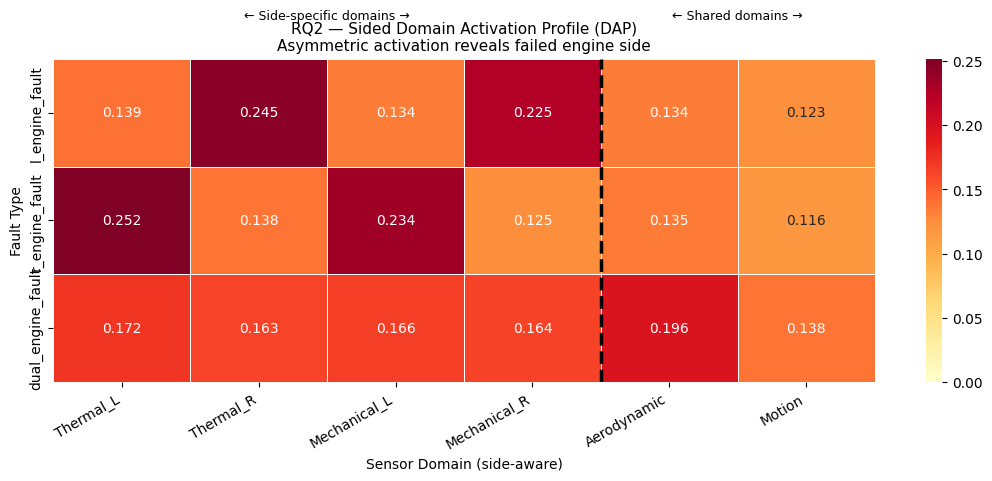

✅ Sided DAP saved


In [ ]:
# ── Plot sided DAP heatmap ───────────────────────────────────

fig, ax = plt.subplots(figsize=(11, 5))

sns.heatmap(
    sided_dap_matrix,
    annot       = True,
    fmt         = ".3f",
    xticklabels = sided_domain_list,
    yticklabels = list(RQ2_LABEL_NAMES.values()),
    cmap        = "YlOrRd",
    linewidths  = 0.5,
    linecolor   = "white",
    ax          = ax,
    vmin        = 0
)

# Draw separator between sided and combined domains
ax.axvline(4, color="black", linewidth=2.5, linestyle="--")
ax.text(2.0, -0.4, "← Side-specific domains →",
        ha="center", va="center", fontsize=9,
        transform=ax.transData)
ax.text(5.0, -0.4, "← Shared domains →",
        ha="center", va="center", fontsize=9,
        transform=ax.transData)

ax.set_title(
    "RQ2 — Sided Domain Activation Profile (DAP)\n"
    "Asymmetric activation reveals failed engine side",
    fontsize=11
)
ax.set_xlabel("Sensor Domain (side-aware)")
ax.set_ylabel("Fault Type")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(SAVE_PATH, "sided_dap_heatmap.png"),
            dpi=150, bbox_inches="tight")
plt.show()

np.save(os.path.join(SAVE_PATH, "sided_dap_matrix.npy"),
        sided_dap_matrix)
print("✅ Sided DAP saved")

In [ ]:
# ── Asymmetry ratio: key metric for paper ────────────────────

print("=" * 60)
print("SIDED DAP — ASYMMETRY ANALYSIS")
print("=" * 60)

for lbl, lbl_name in RQ2_LABEL_NAMES.items():
    th_l  = sided_dap_matrix[lbl, sided_domain_list.index("Thermal_L")]
    th_r  = sided_dap_matrix[lbl, sided_domain_list.index("Thermal_R")]
    me_l  = sided_dap_matrix[lbl, sided_domain_list.index("Mechanical_L")]
    me_r  = sided_dap_matrix[lbl, sided_domain_list.index("Mechanical_R")]

    th_asym = (th_l - th_r) / (th_l + th_r + 1e-9)
    me_asym = (me_l - me_r) / (me_l + me_r + 1e-9)

    print(f"\n  {lbl_name}:")
    print(f"    Thermal   L={th_l:.4f}  R={th_r:.4f}  "
          f"asymmetry={th_asym:+.4f}")
    print(f"    Mechanical L={me_l:.4f}  R={me_r:.4f}  "
          f"asymmetry={me_asym:+.4f}")

print("""
INTERPRETATION:
  L engine fault  → Thermal_L > Thermal_R, Mechanical_L > Mechanical_R
  R engine fault  → Thermal_R > Thermal_L, Mechanical_R > Mechanical_L
  Dual engine     → Both sides approximately equal
  Asymmetry ratio → positive = left dominant, negative = right dominant
""")

SIDED DAP — ASYMMETRY ANALYSIS

  l_engine_fault:
    Thermal   L=0.1387  R=0.2447  asymmetry=-0.2765
    Mechanical L=0.1344  R=0.2253  asymmetry=-0.2527

  r_engine_fault:
    Thermal   L=0.2515  R=0.1376  asymmetry=+0.2928
    Mechanical L=0.2340  R=0.1250  asymmetry=+0.3036

  dual_engine_fault:
    Thermal   L=0.1722  R=0.1635  asymmetry=+0.0259
    Mechanical L=0.1662  R=0.1643  asymmetry=+0.0058

INTERPRETATION:
  L engine fault  → Thermal_L > Thermal_R, Mechanical_L > Mechanical_R
  R engine fault  → Thermal_R > Thermal_L, Mechanical_R > Mechanical_L
  Dual engine     → Both sides approximately equal
  Asymmetry ratio → positive = left dominant, negative = right dominant



In [ ]:
# ============================================================
# FIX 2 — GRADCAM CHANNEL ATTRIBUTION
# True gradient-based channel importance
# per fault type across test set
# ============================================================

model.eval()

gradcam_accum  = {lbl: np.zeros(len(RQ2_CHANNELS))
                  for lbl in range(3)}
gradcam_counts = {lbl: 0 for lbl in range(3)}

for i in range(len(X_test_norm)):
    lbl = int(all_labels[i])

    x = torch.FloatTensor(X_test_norm[i:i+1]).to(device)
    x.requires_grad_(True)

    # Forward pass
    logits = model(x)

    # Gradient of predicted class score w.r.t. input
    model.zero_grad()
    target_score = logits[0, lbl]
    target_score.backward()

    # x.grad shape: [1 × 450 × 23]
    # Take mean absolute gradient across timesteps → [23]
    grad = x.grad[0].abs().mean(dim=0).detach().cpu().numpy()

    gradcam_accum[lbl]  += grad
    gradcam_counts[lbl] += 1

# Average per fault type
gradcam_matrix = np.zeros((3, len(RQ2_CHANNELS)))
for lbl in range(3):
    if gradcam_counts[lbl] > 0:
        gradcam_matrix[lbl] = (
            gradcam_accum[lbl] / gradcam_counts[lbl]
        )
    # Normalize row to sum to 1
    row_sum = gradcam_matrix[lbl].sum()
    if row_sum > 0:
        gradcam_matrix[lbl] /= row_sum

print("✅ GradCAM attribution computed")
print(f"   Shape: {gradcam_matrix.shape}  "
      f"[fault_types × channels]")

✅ GradCAM attribution computed
   Shape: (3, 23)  [fault_types × channels]


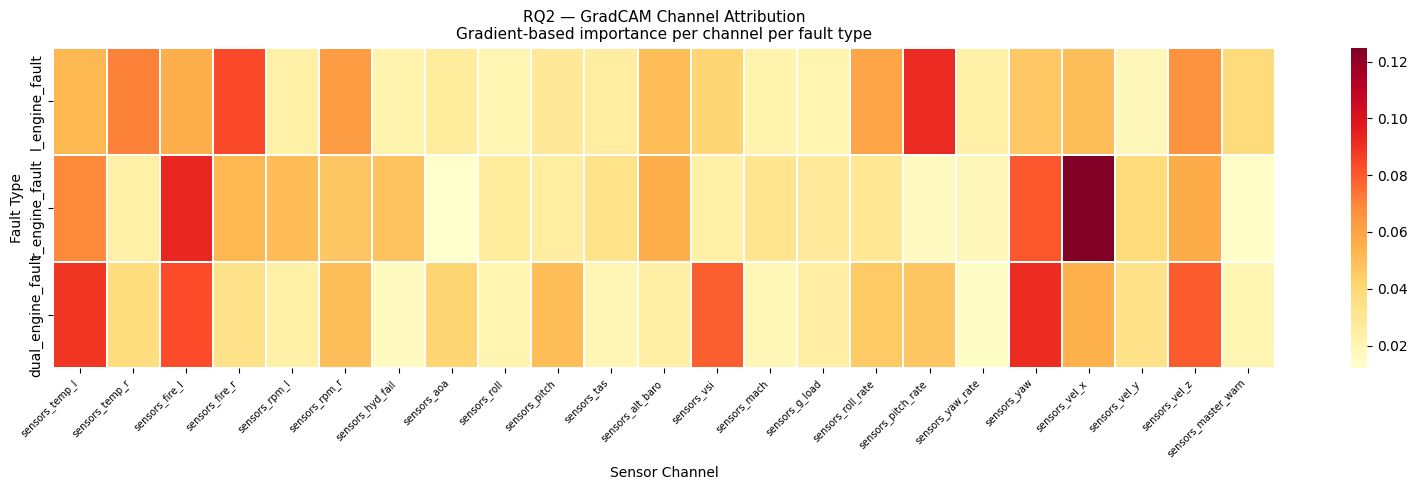

In [ ]:
# ── GradCAM heatmap — per channel ────────────────────────────

fig, ax = plt.subplots(figsize=(16, 5))

sns.heatmap(
    gradcam_matrix,
    annot       = False,
    xticklabels = RQ2_CHANNELS,
    yticklabels = list(RQ2_LABEL_NAMES.values()),
    cmap        = "YlOrRd",
    linewidths  = 0.3,
    ax          = ax,
)
ax.set_title(
    "RQ2 — GradCAM Channel Attribution\n"
    "Gradient-based importance per channel per fault type",
    fontsize=11
)
ax.set_xlabel("Sensor Channel")
ax.set_ylabel("Fault Type")
plt.xticks(rotation=45, ha="right", fontsize=7)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_PATH, "gradcam_channels.png"),
            dpi=150, bbox_inches="tight")
plt.show()

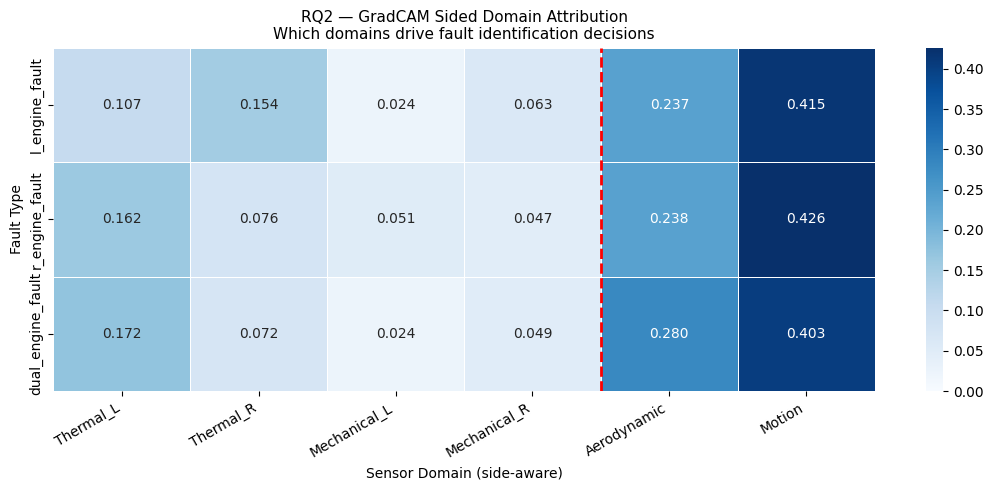

✅ GradCAM results saved


In [ ]:
# ── GradCAM grouped by sided domains ─────────────────────────

gradcam_sided = np.zeros((3, len(sided_domain_list)))

for lbl in range(3):
    for d_idx in range(len(sided_domain_list)):
        mask = ch_sided_domain_idx == d_idx
        if mask.sum() > 0:
            gradcam_sided[lbl, d_idx] = (
                gradcam_matrix[lbl, mask].sum()
            )
    row_sum = gradcam_sided[lbl].sum()
    if row_sum > 0:
        gradcam_sided[lbl] /= row_sum

# Plot
fig, ax = plt.subplots(figsize=(11, 5))
sns.heatmap(
    gradcam_sided,
    annot       = True,
    fmt         = ".3f",
    xticklabels = sided_domain_list,
    yticklabels = list(RQ2_LABEL_NAMES.values()),
    cmap        = "Blues",
    linewidths  = 0.5,
    linecolor   = "white",
    ax          = ax,
    vmin        = 0
)
ax.axvline(4, color="red", linewidth=2, linestyle="--")
ax.set_title(
    "RQ2 — GradCAM Sided Domain Attribution\n"
    "Which domains drive fault identification decisions",
    fontsize=11
)
ax.set_xlabel("Sensor Domain (side-aware)")
ax.set_ylabel("Fault Type")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(os.path.join(SAVE_PATH, "gradcam_sided_domains.png"),
            dpi=150, bbox_inches="tight")
plt.show()

np.save(os.path.join(SAVE_PATH, "gradcam_matrix.npy"),
        gradcam_matrix)
np.save(os.path.join(SAVE_PATH, "gradcam_sided.npy"),
        gradcam_sided)
print("✅ GradCAM results saved")

In [ ]:
# ── GradCAM top channels per fault type ──────────────────────

print("=" * 60)
print("GRADCAM — TOP 5 CHANNELS PER FAULT TYPE")
print("=" * 60)

for lbl, lbl_name in RQ2_LABEL_NAMES.items():
    ch_importance = gradcam_matrix[lbl]
    top_idx       = np.argsort(ch_importance)[::-1][:5]
    print(f"\n  {lbl_name}:")
    for rank, idx in enumerate(top_idx):
        print(f"    {rank+1}. {RQ2_CHANNELS[idx]:30s}: "
              f"{ch_importance[idx]:.4f}")

# ── Asymmetry check via GradCAM ───────────────────────────────
print("\n" + "=" * 60)
print("GRADCAM — SIDED ASYMMETRY ANALYSIS")
print("=" * 60)

for lbl, lbl_name in RQ2_LABEL_NAMES.items():
    th_l = gradcam_sided[lbl, sided_domain_list.index("Thermal_L")]
    th_r = gradcam_sided[lbl, sided_domain_list.index("Thermal_R")]
    me_l = gradcam_sided[lbl, sided_domain_list.index("Mechanical_L")]
    me_r = gradcam_sided[lbl, sided_domain_list.index("Mechanical_R")]

    th_asym = (th_l - th_r) / (th_l + th_r + 1e-9)
    me_asym = (me_l - me_r) / (me_l + me_r + 1e-9)

    print(f"\n  {lbl_name}:")
    print(f"    Thermal    L={th_l:.4f}  R={th_r:.4f}  "
          f"asymmetry={th_asym:+.4f}")
    print(f"    Mechanical L={me_l:.4f}  R={me_r:.4f}  "
          f"asymmetry={me_asym:+.4f}")

GRADCAM — TOP 5 CHANNELS PER FAULT TYPE

  l_engine_fault:
    1. sensors_pitch_rate            : 0.0920
    2. sensors_fire_r                : 0.0838
    3. sensors_temp_r                : 0.0707
    4. sensors_vel_z                 : 0.0658
    5. sensors_rpm_r                 : 0.0626

  r_engine_fault:
    1. sensors_vel_x                 : 0.1249
    2. sensors_fire_l                : 0.0930
    3. sensors_yaw                   : 0.0805
    4. sensors_temp_l                : 0.0691
    5. sensors_vel_z                 : 0.0565

  dual_engine_fault:
    1. sensors_yaw                   : 0.0918
    2. sensors_temp_l                : 0.0890
    3. sensors_fire_l                : 0.0834
    4. sensors_vel_z                 : 0.0795
    5. sensors_vsi                   : 0.0790

GRADCAM — SIDED ASYMMETRY ANALYSIS

  l_engine_fault:
    Thermal    L=0.1075  R=0.1544  asymmetry=-0.1793
    Mechanical L=0.0242  R=0.0626  asymmetry=-0.4425

  r_engine_fault:
    Thermal    L=0.1621  R=0.0

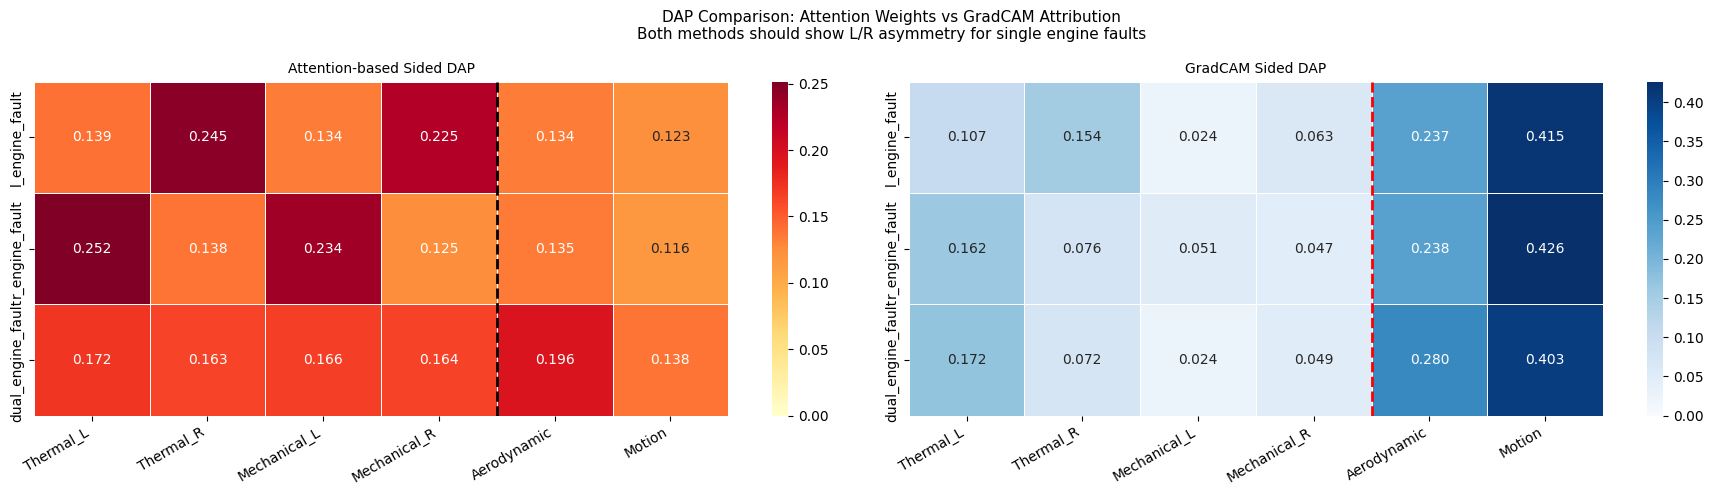

In [ ]:
# ── Compare attention DAP vs GradCAM DAP ─────────────────────

fig, axes = plt.subplots(1, 2, figsize=(18, 5))

# Attention-based sided DAP
sns.heatmap(
    sided_dap_matrix,
    annot       = True, fmt=".3f",
    xticklabels = sided_domain_list,
    yticklabels = list(RQ2_LABEL_NAMES.values()),
    cmap="YlOrRd", linewidths=0.5,
    ax=axes[0], vmin=0
)
axes[0].set_title("Attention-based Sided DAP", fontsize=10)
axes[0].axvline(4, color="black", linewidth=2, linestyle="--")
plt.setp(axes[0].get_xticklabels(), rotation=30, ha="right")

# GradCAM sided DAP
sns.heatmap(
    gradcam_sided,
    annot       = True, fmt=".3f",
    xticklabels = sided_domain_list,
    yticklabels = list(RQ2_LABEL_NAMES.values()),
    cmap="Blues", linewidths=0.5,
    ax=axes[1], vmin=0
)
axes[1].set_title("GradCAM Sided DAP", fontsize=10)
axes[1].axvline(4, color="red", linewidth=2, linestyle="--")
plt.setp(axes[1].get_xticklabels(), rotation=30, ha="right")

plt.suptitle(
    "DAP Comparison: Attention Weights vs GradCAM Attribution\n"
    "Both methods should show L/R asymmetry for single engine faults",
    fontsize=11
)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_PATH, "dap_comparison.png"),
            dpi=150, bbox_inches="tight")
plt.show()

## Shap Analysis

In [ ]:
# ============================================================
# CELL 7 — SHAP ANALYSIS (RQ1) — 4 LEVELS
# ============================================================

print("Computing SHAP values (this may take 2–5 minutes)...")

explainer   = shap.TreeExplainer(best_xgb)
shap_values = explainer.shap_values(X_test_rq1)
# shap_values: list of 4 arrays, one per class, each [n_test × n_features]

print(f"✅ SHAP values computed — shape per class: {shap_values[0].shape}")

Computing SHAP values (this may take 2–5 minutes)...
✅ SHAP values computed — shape per class: (789, 4)


### Global Feature Analysis

In [ ]:
# ============================================================
# SHAP ANALYSIS — ALL 4 LEVELS (corrected for shape 4143×789×4)
# Format: shap_values[n_samples × n_features × n_classes]
# ============================================================

# ── Helper ───────────────────────────────────────────────────
def get_class_shap(sv, class_idx):
    """Returns [n_samples × n_features] for a given class."""
    return sv[:, :, class_idx]

n_classes = 4

# ── Global mean absolute SHAP across all classes ─────────────
mean_abs_shap = np.abs(shap_values).mean(axis=(0, 2))   # [n_features]

print(f"mean_abs_shap shape : {mean_abs_shap.shape}")
print(f"FEATURE_COLS count  : {len(FEATURE_COLS)}")
assert len(mean_abs_shap) == len(FEATURE_COLS), \
    f"Mismatch: {len(mean_abs_shap)} vs {len(FEATURE_COLS)}"
print("✅ Shape check passed")

mean_abs_shap shape : (789,)
FEATURE_COLS count  : 789
✅ Shape check passed


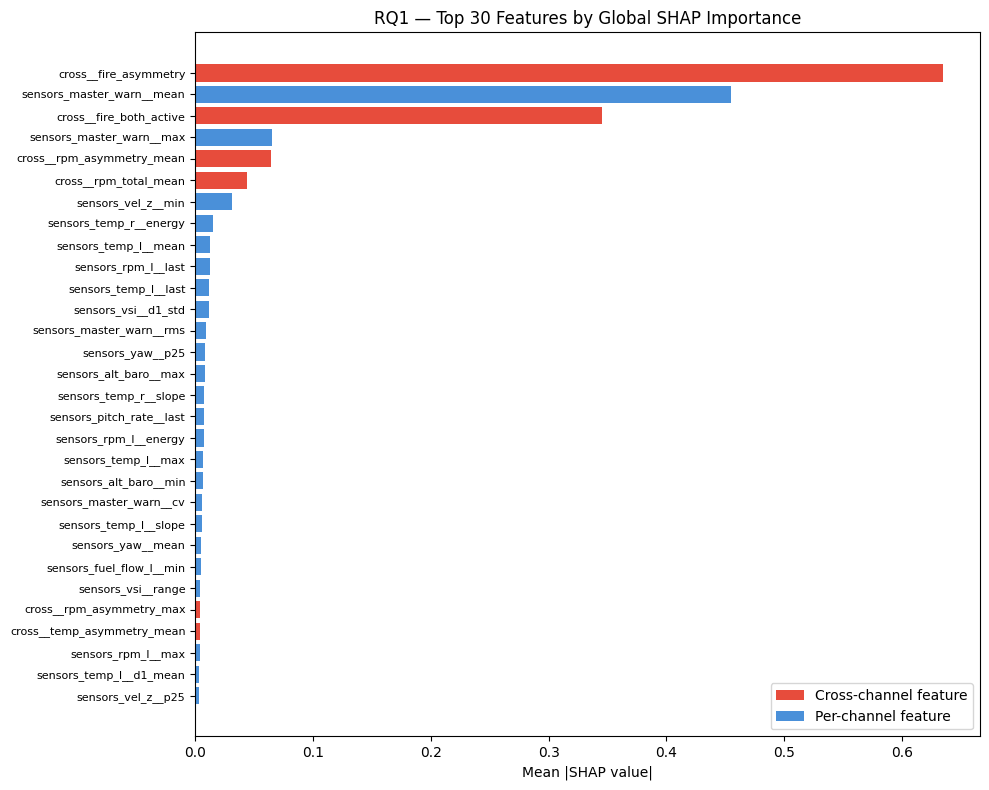


Top 10 features globally:
   1. cross__fire_asymmetry                             : 0.634510
   2. sensors_master_warn__mean                         : 0.454399
   3. cross__fire_both_active                           : 0.345547
   4. sensors_master_warn__max                          : 0.065040
   5. cross__rpm_asymmetry_mean                         : 0.064262
   6. cross__rpm_total_mean                             : 0.044048
   7. sensors_vel_z__min                                : 0.031147
   8. sensors_temp_r__energy                            : 0.014698
   9. sensors_temp_l__mean                              : 0.012564
  10. sensors_rpm_l__last                               : 0.012348


In [ ]:
# ============================================================
# LEVEL 1 — GLOBAL FEATURE IMPORTANCE
# ============================================================

top_n    = 30
top_idx  = np.argsort(mean_abs_shap)[::-1][:top_n]
top_fts  = [FEATURE_COLS[i] for i in top_idx]
top_vals = mean_abs_shap[top_idx]

fig, ax  = plt.subplots(figsize=(10, 8))
colors   = ["#E74C3C" if "cross" in f else "#4A90D9" for f in top_fts]
y_pos    = np.arange(top_n)

ax.barh(y_pos, top_vals[::-1], color=colors[::-1])
ax.set_yticks(y_pos)
ax.set_yticklabels(top_fts[::-1], fontsize=8)
ax.set_xlabel("Mean |SHAP value|")
ax.set_title(f"RQ1 — Top {top_n} Features by Global SHAP Importance")

from matplotlib.patches import Patch
ax.legend(handles=[
    Patch(facecolor="#E74C3C", label="Cross-channel feature"),
    Patch(facecolor="#4A90D9", label="Per-channel feature")
], loc="lower right")

plt.tight_layout()
plt.savefig(os.path.join(SAVE_PATH, "shap_global_importance.png"), dpi=150)
plt.show()

print("\nTop 10 features globally:")
for i, (f, v) in enumerate(zip(top_fts[:10], top_vals[:10])):
    print(f"  {i+1:2d}. {f:50s}: {v:.6f}")

### Per-Class SHAP

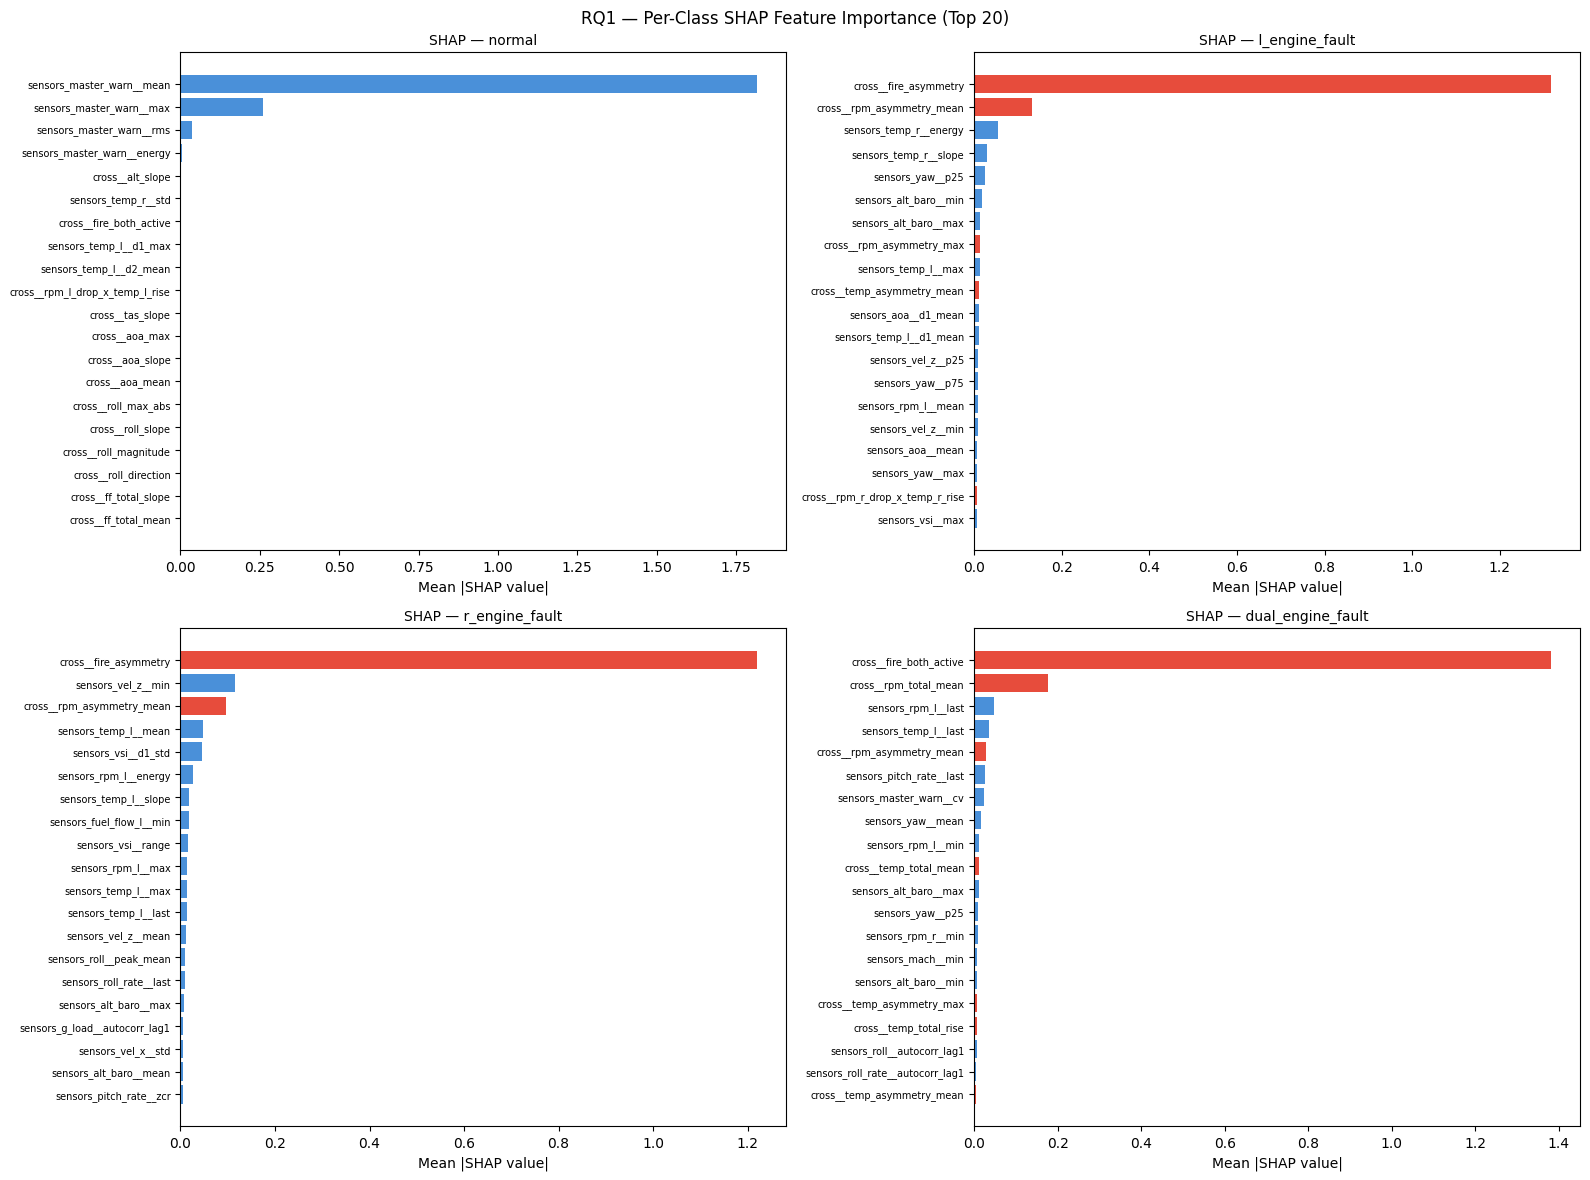

In [ ]:
# ============================================================
# LEVEL 2 — PER-CLASS SHAP (Top 20 per fault type)
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(16, 12))

for cls_idx, (cls_name, ax) in enumerate(
    zip(LABEL_NAMES.values(), axes.flat)
):
    cls_shap     = np.abs(get_class_shap(shap_values, cls_idx)).mean(axis=0)
    top_idx_cls  = np.argsort(cls_shap)[::-1][:20]
    top_fts_cls  = [FEATURE_COLS[i] for i in top_idx_cls]
    top_val_cls  = cls_shap[top_idx_cls]

    colors_cls   = ["#E74C3C" if "cross" in f else "#4A90D9"
                    for f in top_fts_cls]
    y_pos_cls    = np.arange(20)

    ax.barh(y_pos_cls, top_val_cls[::-1], color=colors_cls[::-1])
    ax.set_yticks(y_pos_cls)
    ax.set_yticklabels(top_fts_cls[::-1], fontsize=7)
    ax.set_title(f"SHAP — {cls_name}", fontsize=10)
    ax.set_xlabel("Mean |SHAP value|")

plt.suptitle("RQ1 — Per-Class SHAP Feature Importance (Top 20)",
             fontsize=12)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_PATH, "shap_per_class.png"), dpi=150)
plt.show()

### Domain Contribution

Domain SHAP Contribution (%) per fault type:


,Thermal,Mechanical,Aerodynamic,Motion
normal,0.000000,0.000000,0.000000,100.000000
l_engine_fault,34.619999,4.700000,32.090000,28.590000
r_engine_fault,22.379999,10.770000,29.820000,37.029999
dual_engine_fault,15.330000,18.530001,32.279999,33.869999


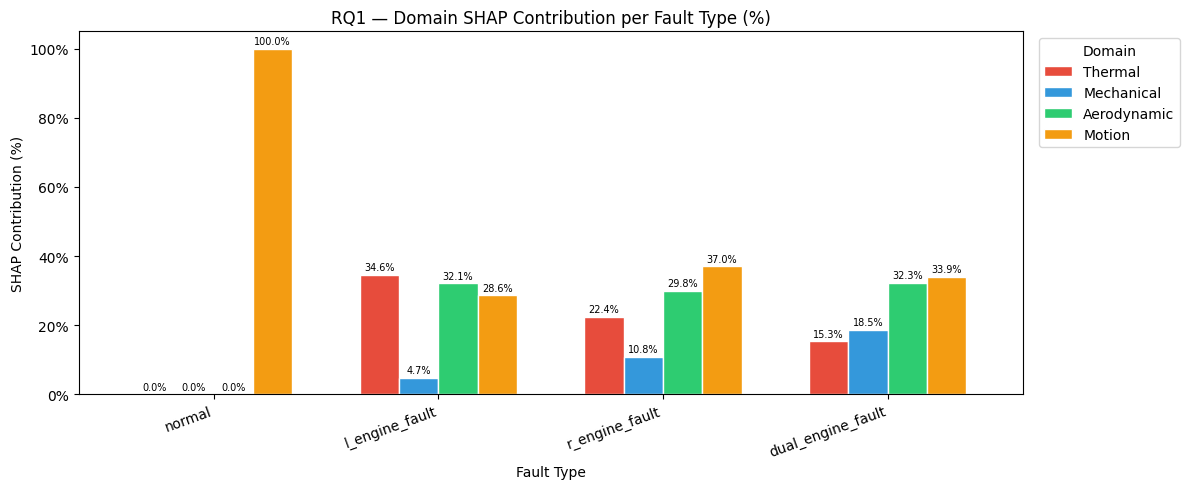

✅ Domain contribution saved


In [ ]:
# ============================================================
# LEVEL 3 — DOMAIN CONTRIBUTION (RQ1 ANSWER)
# ============================================================

domain_shap = {}

for cls_idx, cls_name in LABEL_NAMES.items():
    cls_shap      = np.abs(
        get_class_shap(shap_values, cls_idx)
    ).mean(axis=0)                              # [n_features]

    domain_totals = {}
    for domain, channels in DOMAIN_MAP.items():
        domain_feat_idx = [
            i for i, f in enumerate(FEATURE_COLS)
            if any(ch in f for ch in channels)
        ]
        domain_totals[domain] = (
            cls_shap[domain_feat_idx].sum()
            if domain_feat_idx else 0.0
        )

    # Normalize to percentage
    total = sum(domain_totals.values())
    domain_shap[cls_name] = {
        d: (v / total * 100 if total > 0 else 0.0)
        for d, v in domain_totals.items()
    }

domain_df = pd.DataFrame(domain_shap).T
print("Domain SHAP Contribution (%) per fault type:")
display(domain_df.round(2))

# ── Bar chart ────────────────────────────────────────────────
fig, ax  = plt.subplots(figsize=(12, 5))
colors_d = ["#E74C3C", "#3498DB", "#2ECC71", "#F39C12"]

domain_df.plot(
    kind      = "bar",
    ax        = ax,
    color     = colors_d,
    edgecolor = "white",
    width     = 0.7
)
ax.set_title(
    "RQ1 — Domain SHAP Contribution per Fault Type (%)",
    fontsize=12
)
ax.set_xlabel("Fault Type")
ax.set_ylabel("SHAP Contribution (%)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=20, ha="right")
ax.legend(title="Domain", bbox_to_anchor=(1.01, 1), loc="upper left")
ax.yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"{x:.0f}%")
)

# Add value labels on bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", fontsize=7, padding=2)

plt.tight_layout()
plt.savefig(
    os.path.join(SAVE_PATH, "shap_domain_contribution.png"),
    dpi=150, bbox_inches="tight"
)
plt.show()

# Save domain contribution table
domain_df.to_parquet(
    os.path.join(SAVE_PATH, "shap_domain_contribution.parquet")
)
print("✅ Domain contribution saved")

### Shap Shift at Fault Onset

Pre-fault windows  (from fault flights): 1,149
Post-fault windows (from fault flights): 1,396
Computing pre-fault SHAP values...
Computing post-fault SHAP values...

Top 15 features with largest rank shift at fault onset:


,rank_shift
sensors_pitch_rate__p75,250.0
sensors_vel_y__range,230.0
sensors_alt_baro__iqr,212.0
sensors_alt_baro__range,199.0
sensors_rpm_l__slope,179.0
sensors_rpm_l__rms,179.0
sensors_temp_l__delta,177.0
sensors_alt_baro__cv,175.0
sensors_temp_r__first,169.0
sensors_roll_rate__zcr,167.0


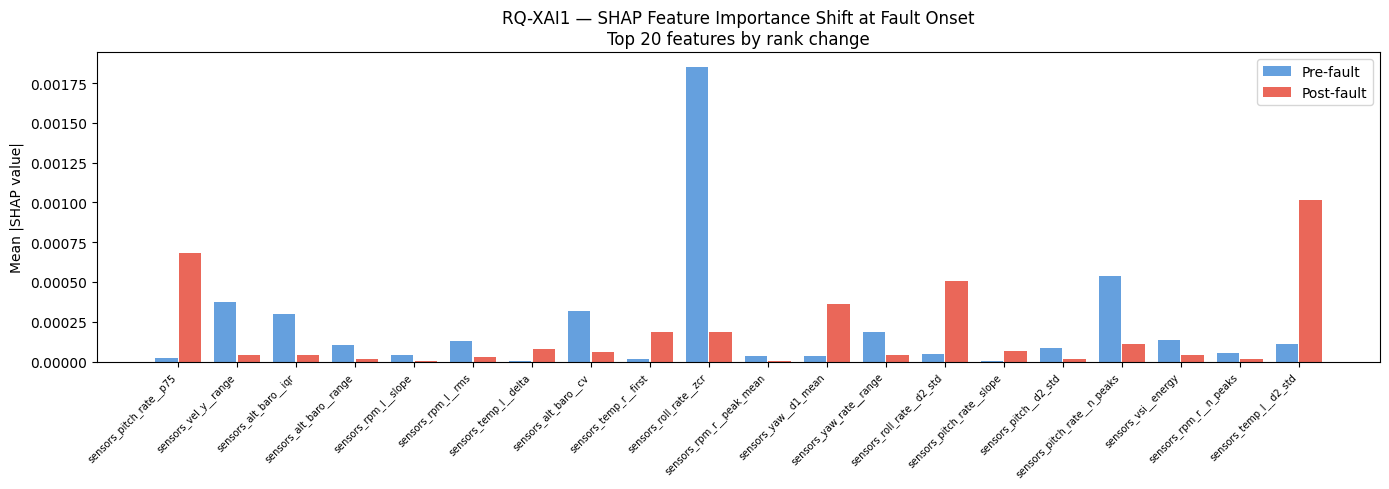


Domain-level SHAP shift (pre → post fault onset):
  Thermal        : pre=0.0392  post=0.1625  change=+314.5% ↑
  Mechanical     : pre=0.0341  post=0.0526  change=+54.4% ↑
  Aerodynamic    : pre=0.1052  post=0.1068  change=+1.5% ↑
  Motion         : pre=0.6914  post=0.5040  change=-27.1% ↓

✅ SHAP analysis complete — all 4 levels done


In [ ]:
# ============================================================
# LEVEL 4 — SHAP SHIFT AT FAULT ONSET (RQ-XAI1)
# Compare feature importance in pre-fault vs post-fault windows
# ============================================================

# ── Get pre/post fault windows from test fault flights ────────
rq1_test_df = rq1_df[rq1_df[FLIGHT_COL].isin(test_flights)].copy()
fault_test   = rq1_test_df[rq1_test_df["mission_type"] != BASELINE]

pre_rows  = fault_test[fault_test["label"] == 0]   # fault flight, pre-onset window
post_rows = fault_test[fault_test["label"] >  0]   # fault flight, post-onset window

print(f"Pre-fault windows  (from fault flights): {len(pre_rows):,}")
print(f"Post-fault windows (from fault flights): {len(post_rows):,}")

# Sample to keep SHAP computation fast (max 500 each)
pre_sample  = pre_rows.sample(min(500, len(pre_rows)),   random_state=SEED)
post_sample = post_rows.sample(min(500, len(post_rows)), random_state=SEED)

pre_X  = scaler_rq1.transform(
    pre_sample[FEATURE_COLS].values.astype(np.float32)
)
post_X = scaler_rq1.transform(
    post_sample[FEATURE_COLS].values.astype(np.float32)
)

# ── Compute SHAP on pre and post separately ───────────────────
print("Computing pre-fault SHAP values...")
pre_shap_vals  = explainer.shap_values(pre_X)    # [n_samples × n_features × n_classes]

print("Computing post-fault SHAP values...")
post_shap_vals = explainer.shap_values(post_X)

# Mean absolute SHAP across all classes
if isinstance(pre_shap_vals, list):
    pre_shap_all  = np.mean(
        [np.abs(pre_shap_vals[c])  for c in range(n_classes)], axis=0
    ).mean(axis=0)
    post_shap_all = np.mean(
        [np.abs(post_shap_vals[c]) for c in range(n_classes)], axis=0
    ).mean(axis=0)
else:
    pre_shap_all  = np.abs(pre_shap_vals).mean(axis=(0, 2))
    post_shap_all = np.abs(post_shap_vals).mean(axis=(0, 2))

# ── Rank shift analysis ───────────────────────────────────────
pre_rank  = pd.Series(pre_shap_all,  index=FEATURE_COLS).rank(ascending=False)
post_rank = pd.Series(post_shap_all, index=FEATURE_COLS).rank(ascending=False)
rank_shift = (post_rank - pre_rank).abs().sort_values(ascending=False)

print("\nTop 15 features with largest rank shift at fault onset:")
display(rank_shift.head(15).to_frame("rank_shift").round(1))

# ── Bar chart: pre vs post importance for top shifted features ─
top_shift_feats = rank_shift.head(20).index.tolist()
pre_vals_plot   = np.array([
    pre_shap_all[FEATURE_COLS.index(f)]  for f in top_shift_feats
])
post_vals_plot  = np.array([
    post_shap_all[FEATURE_COLS.index(f)] for f in top_shift_feats
])

x_pos = np.arange(len(top_shift_feats))
fig, ax = plt.subplots(figsize=(14, 5))
ax.bar(x_pos - 0.2, pre_vals_plot,  0.38,
       label="Pre-fault",  color="#4A90D9", alpha=0.85)
ax.bar(x_pos + 0.2, post_vals_plot, 0.38,
       label="Post-fault", color="#E74C3C", alpha=0.85)
ax.set_xticks(x_pos)
ax.set_xticklabels(top_shift_feats, rotation=45, ha="right", fontsize=7)
ax.set_title(
    "RQ-XAI1 — SHAP Feature Importance Shift at Fault Onset\n"
    "Top 20 features by rank change"
)
ax.set_ylabel("Mean |SHAP value|")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(SAVE_PATH, "shap_onset_shift.png"), dpi=150)
plt.show()

# ── Domain-level shift ─────────────────────────────────────────
print("\nDomain-level SHAP shift (pre → post fault onset):")
for domain, channels in DOMAIN_MAP.items():
    d_idx = [
        i for i, f in enumerate(FEATURE_COLS)
        if any(ch in f for ch in channels)
    ]
    pre_d  = pre_shap_all[d_idx].sum()  if d_idx else 0.0
    post_d = post_shap_all[d_idx].sum() if d_idx else 0.0
    change = ((post_d - pre_d) / pre_d * 100) if pre_d > 0 else 0.0
    direction = "↑" if change > 0 else "↓"
    print(f"  {domain:15s}: pre={pre_d:.4f}  post={post_d:.4f}  "
          f"change={change:+.1f}% {direction}")

# Save rank shift
rank_shift.to_frame("rank_shift").to_parquet(
    os.path.join(SAVE_PATH, "shap_rank_shift.parquet")
)
print("\n✅ SHAP analysis complete — all 4 levels done")

### Assymmetry Health Index

In [ ]:
# ============================================================
# CELL 8 — ASYMMETRY HEALTH INDEX (RQ-SEV3)
# ============================================================

ahi_features = [
    "cross__rpm_asymmetry_mean",
    "cross__temp_asymmetry_mean",
    "cross__roll_direction",
    "cross__fire_asymmetry",
    "cross__rpm_l_drop_x_temp_l_rise",
    "cross__rpm_r_drop_x_temp_r_rise",
]
ahi_features = [f for f in ahi_features if f in FEATURE_COLS]

print(f"AHI features found: {len(ahi_features)}")
print(f"Features: {ahi_features}")

# ── SHAP-derived weights (fault classes only, skip normal) ────
ahi_shap_weights = np.array([
    np.mean([
        np.abs(
            get_class_shap(shap_values, c)[:, FEATURE_COLS.index(f)]
        ).mean()
        for c in range(1, 4)   # 1=l_engine, 2=r_engine, 3=dual
    ])
    for f in ahi_features
])
ahi_shap_weights /= ahi_shap_weights.sum()

print("\nAHI feature weights (SHAP-derived):")
for f, w in zip(ahi_features, ahi_shap_weights):
    print(f"  {f:50s}: {w:.4f}")

AHI features found: 6
Features: ['cross__rpm_asymmetry_mean', 'cross__temp_asymmetry_mean', 'cross__roll_direction', 'cross__fire_asymmetry', 'cross__rpm_l_drop_x_temp_l_rise', 'cross__rpm_r_drop_x_temp_r_rise']

AHI feature weights (SHAP-derived):
  cross__rpm_asymmetry_mean                         : 0.0912
  cross__temp_asymmetry_mean                        : 0.0058
  cross__roll_direction                             : 0.0000
  cross__fire_asymmetry                             : 0.9005
  cross__rpm_l_drop_x_temp_l_rise                   : 0.0001
  cross__rpm_r_drop_x_temp_r_rise                   : 0.0023


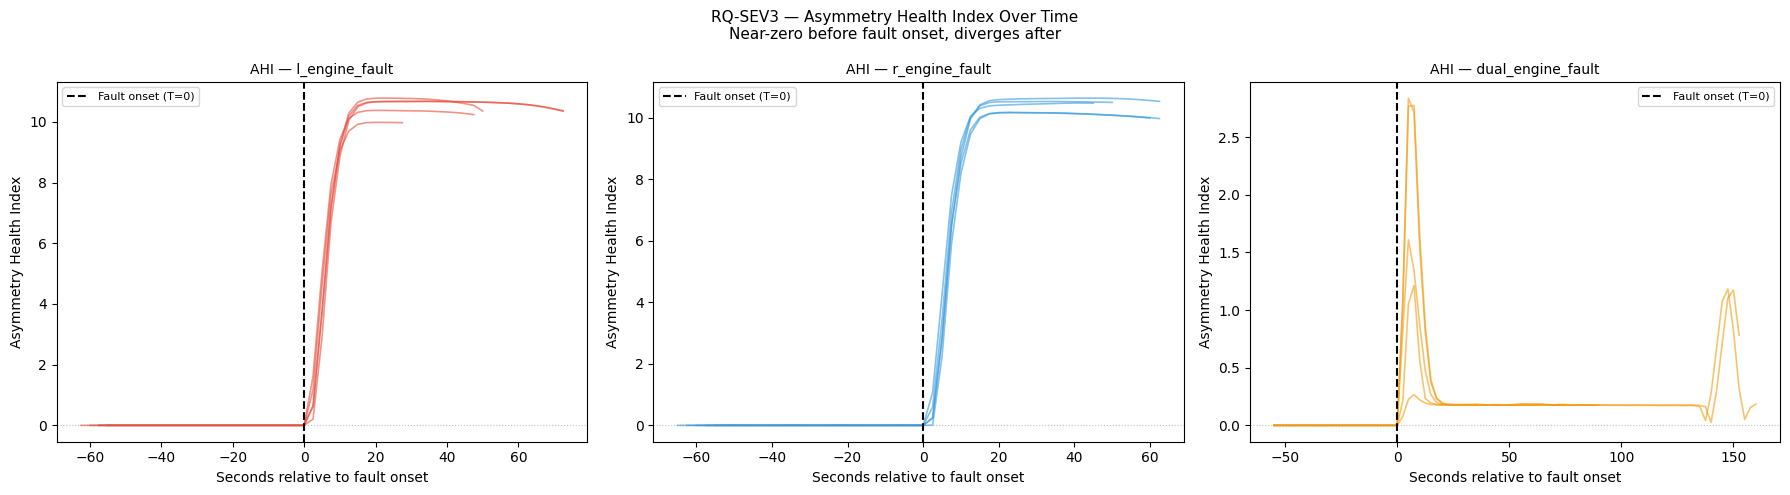

In [ ]:
# ── Compute AHI trajectory per flight ────────────────────────

fault_types_plot = [
    ("l_engine_fault",    "#E74C3C"),
    ("r_engine_fault",    "#3498DB"),
    ("dual_engine_fault", "#F39C12"),
]

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=False)

for ax, (ftype, color) in zip(axes, fault_types_plot):

    sample_fids = (
        rq1_df[rq1_df["mission_type"] == ftype][FLIGHT_COL]
        .unique()[:5]
    )

    for fid in sample_fids:
        fdf = rq1_df[rq1_df[FLIGHT_COL] == fid].sort_values("w_start")

        if len(fdf) < 3:
            continue

        # ── Compute AHI per window ────────────────────────
        ahi_vals = []
        for _, row in fdf.iterrows():
            feat_vals = np.array([
                abs(row[f]) if f in row.index else 0.0
                for f in ahi_features
            ])
            ahi_vals.append(float(np.dot(ahi_shap_weights, feat_vals)))

        # ── Time axis relative to fault onset ─────────────
        t_mid = (fdf["w_start"].values + fdf["w_end"].values) / 2.0

        fault_onset_rows = rq1_df[
            (rq1_df[FLIGHT_COL] == fid) &
            (rq1_df["label"] > 0)
        ]
        if len(fault_onset_rows) > 0:
            fault_onset = fault_onset_rows["w_start"].min()
        else:
            fault_onset = np.nan

        t_rel = (t_mid - fault_onset
                 if not np.isnan(fault_onset)
                 else t_mid)

        ax.plot(t_rel, ahi_vals,
                alpha=0.6, linewidth=1.2, color=color)

    ax.axvline(0, color="black", linestyle="--",
               linewidth=1.5, label="Fault onset (T=0)")
    ax.axhline(0, color="gray", linestyle=":",
               linewidth=0.8, alpha=0.5)
    ax.set_title(f"AHI — {ftype}", fontsize=10)
    ax.set_xlabel("Seconds relative to fault onset")
    ax.set_ylabel("Asymmetry Health Index")
    ax.legend(fontsize=8)

plt.suptitle(
    "RQ-SEV3 — Asymmetry Health Index Over Time\n"
    "Near-zero before fault onset, diverges after",
    fontsize=11
)
plt.tight_layout()
plt.savefig(os.path.join(SAVE_PATH, "ahi_trajectories.png"), dpi=150)
plt.show()

In [ ]:
# ── AHI summary stats per mission type ───────────────────────

print("=" * 60)
print("AHI SUMMARY STATS PER MISSION TYPE")
print("=" * 60)

# Compute AHI for all windows in rq1_df
print("Computing AHI for all windows...")

all_ahi = []
for _, row in rq1_df.iterrows():
    feat_vals = np.array([
        abs(row[f]) if f in row.index else 0.0
        for f in ahi_features
    ])
    all_ahi.append(float(np.dot(ahi_shap_weights, feat_vals)))

rq1_df["ahi"] = all_ahi

print("\nAHI statistics per mission type:")
display(
    rq1_df.groupby("mission_type")["ahi"]
    .agg(["mean", "std", "min", "max"])
    .round(4)
)

# Pre vs post fault AHI comparison
print("\nAHI pre-fault vs post-fault (fault flights only):")
fault_windows = rq1_df[rq1_df["mission_type"] != BASELINE]

pre_ahi  = fault_windows[fault_windows["label"] == 0]["ahi"]
post_ahi = fault_windows[fault_windows["label"] >  0]["ahi"]

print(f"  Pre-fault  mean AHI : {pre_ahi.mean():.4f}  (std={pre_ahi.std():.4f})")
print(f"  Post-fault mean AHI : {post_ahi.mean():.4f}  (std={post_ahi.std():.4f})")
print(f"  Ratio post/pre      : {post_ahi.mean()/pre_ahi.mean():.2f}x")

AHI SUMMARY STATS PER MISSION TYPE
Computing AHI for all windows...

AHI statistics per mission type:


,mean,std,min,max
mission_type,,,,
baseline,0.0000,0.0000,0.0,0.0001
dual_engine_fault,0.3447,1.3453,0.0,10.9163
l_engine_fault,4.3748,5.0357,0.0,10.9172
r_engine_fault,4.4339,5.0183,0.0,10.7701



AHI pre-fault vs post-fault (fault flights only):
  Pre-fault  mean AHI : 0.0000  (std=0.0000)
  Post-fault mean AHI : 5.3498  (std=4.9453)
  Ratio post/pre      : 38757837.10x


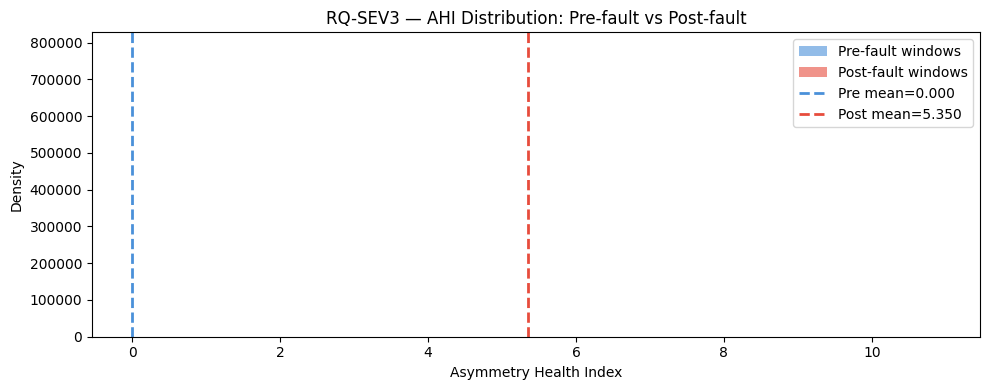

✅ AHI saved


In [ ]:
# ── AHI distribution plot (pre vs post) ──────────────────────

fig, ax = plt.subplots(figsize=(10, 4))

ax.hist(pre_ahi,  bins=50, alpha=0.6,
        color="#4A90D9", label="Pre-fault windows",  density=True)
ax.hist(post_ahi, bins=50, alpha=0.6,
        color="#E74C3C", label="Post-fault windows", density=True)

ax.axvline(pre_ahi.mean(),  color="#4A90D9", linestyle="--",
           linewidth=2, label=f"Pre mean={pre_ahi.mean():.3f}")
ax.axvline(post_ahi.mean(), color="#E74C3C", linestyle="--",
           linewidth=2, label=f"Post mean={post_ahi.mean():.3f}")

ax.set_title("RQ-SEV3 — AHI Distribution: Pre-fault vs Post-fault")
ax.set_xlabel("Asymmetry Health Index")
ax.set_ylabel("Density")
ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(SAVE_PATH, "ahi_distribution.png"), dpi=150)
plt.show()

# Save AHI column
rq1_df[["mission_id", "mission_type", "band",
         "label", "w_start", "w_end", "ahi"]].to_parquet(
    os.path.join(SAVE_PATH, "rq1_ahi.parquet"), index=False
)
print("✅ AHI saved")